# vti-02 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830
from qcodes.instrument_drivers.tektronix.Keithley_2400 import Keithley_2400

import sweep
from sweep import interruptible_sleep
from gui.qt_progress import QtProgress
sweep.set_progress(QtProgress())

from hera.analysis import GateCalibration, field_invB
from sharpelab_nb.closeout import read_state
from sharpelab_nb.constants import VTI
from sharpelab_nb.keithley import assert_keithley_state, normalize_keithley_state
from sharpelab_nb.thermometry import assert_thermometry_live, temperature_from_logfiles

from drivers.FastBi1K5 import FastBi1K5
from drivers.Lakeshore_335 import Lakeshore_335
from drivers.SRS_DC205 import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\DGG\\VTI_local_data\\zack\\20260823-vti-02'

# Connect Instruments

## Magnet

In [3]:
magnet = FastBi1K5('magnet', '192.168.0.10')  # <-- verify address
magnet.status()

Connected to: Fast-Bi-1K5 Magnet Controller
---------- Magnet Status ----------
Field:               : 0.006 Tesla
Current:             : 0.046 A
Voltage:             : 0.000 V
Output Enabled       : True
Persistent Switch On : True
Loop Mode            : CC
Update Mode          : NORMAL
-----------------------------------


## Lakeshore

In [4]:
# heater: LS335 control only (setpoints / ranges / heater power). The lakeshore
# worker (VTI Monitor launcher) is the sole GPIB master on the LS335; per-point
# temperature is read from its logfiles, never over GPIB. fp() these params.
heater = Lakeshore_335('l335_3', 'GPIB0::10::INSTR')

# Liveness gate, hard: rig card cadence 5 s, guard >= 2-3 periods; the legacy
# worker writes ~30 s and a dead one leaves a plausible frozen T on the page.
assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)

T_sample = temperature_from_logfiles("T_sample", VTI.temp_logfile_candidates["T_sample"])
T_vaporizer = temperature_from_logfiles("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"])

print(f"Sample:    {T_sample()} K")
print(f"Vaporizer: {T_vaporizer()} K")

Connected to: LSCI 335 (serial:LSA2FM7/#######, firmware:1.4) in 0.12s
T_sample: VTI_sample.txt live — age 1s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 1s, period 5s
Sample:    1.176 K
Vaporizer: 0.953 K


## Lock-ins

In [5]:
sr0 = SR830('sr0', "GPIB0::22::INSTR")  # <-- verify — current channel (Ithaco preamp output)
sr1 = SR830('sr1', "GPIB0::14::INSTR")  # <-- verify — also the AC drive source
sr2 = SR830('sr2', "GPIB0::19::INSTR")  # <-- verify
sr3 = SR830('sr3', "GPIB0::18::INSTR")  # <-- verify

Connected to: Stanford_Research_Systems SR830 (serial:s/n45620, firmware:ver1.07) in 0.08s
Connected to: Stanford_Research_Systems SR830 (serial:s/n83412, firmware:ver1.07) in 0.08s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr0 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.p

Connected to: Stanford_Research_Systems SR830 (serial:s/n41639, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n93552, firmware:ver1.07) in 0.09s


C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\DGG\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys

In [6]:
k_2400_tg = Keithley_2400('k_2400_tg', 'GPIB0::1::INSTR')  # <-- verify address — top-gate Keithley
k_2400_tg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_tg, rangei=1.05e-6)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1225634, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.03s
k_2400_tg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


In [7]:
k_2400_bg = Keithley_2400('k_2400_bg', 'GPIB0::24::INSTR')  # <-- verify address — back-gate Keithley
k_2400_bg.volt.step = 0.005   # driver-side ramp pacing — software only, dies with the kernel
# Read-first: verify mode/ranges/NPLC/averaging/0 V against the expected table.
# Writes nothing; raises with the deltas on any mismatch (resolve before handoff).
assert_keithley_state(k_2400_bg, rangei=1.05e-6)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:0734554, firmware:C17   Jul 16 1999 15:20:40/A02  /G/F) in 0.03s
k_2400_bg: state verified, no writes — mode=VOLT, rangev=21.0, rangei=1.05e-06, nplci=1.0, volt=+0.0000


## DC205 (Si gate)

In [8]:
dc205 = SRS_DC205("dc205", "ASRL7::INSTR")  # <-- verify address — Si-gate DC205
# Si window is ±50 V ⇒ DC205 must be on its ±100 V range (RNGE 2). Range
# changes require output OFF (front panel) — surface a mismatch, don't force it.
print(f"range code: {dc205.voltage_range()} (need 2 = ±100 V)")
print(f"output on:  {dc205.output()}")
dc205.ramp_rate = 0.5  # V/s — Si dielectric pacing; consent-gated    # <-- validate

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500514, firmware:ver1.80) in 0.05s
range code: 2 (need 2 = ±100 V)
output on:  1


In [9]:
# slot: gate-bindings — role aliases (k_tg/k_bg/k_si) from the device card's
# Gate stack section (which instrument drives which gate). Each value
# `# <-- validate`.

# Gate role aliases (role aliases: k_tg / k_bg / k_si):
k_tg = k_2400_tg   # top gate  <- Keithley 2400 (fast axis k_tg.volt)   # <-- validate
k_bg = k_2400_bg   # back gate <- Keithley 2400                          # <-- validate
# Si gate <- the driver's ramped parameter: set ramps at dc205.ramp_rate,
# get reads back VOLT?. Data column 'dc205_smart_voltage'. No current readback.
k_si = dc205.smart_voltage   # <-- validate

# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [10]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`. Instrument-level fences go on the RAW instruments
# (k_2400_tg / k_2400_bg / dc205); direct calls bypass the role-alias wrapper.
TG_MIN, TG_MAX = -0.3, +1.0    # top gate (k_2400_tg), V     # <-- validate
BG_MIN, BG_MAX = -1.3, +2.0    # back gate (k_2400_bg), V    # <-- validate
SI_MIN, SI_MAX = -25.0, +25.0  # Si gate (dc205), V          # <-- validate
k_2400_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_2400_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)
dc205.smart_voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # k_si sets go through this
dc205.voltage.vals = validators.Numbers(SI_MIN, SI_MAX)  # instrument-level: ramp_voltage sets via dc205.voltage, so this fences ramps too

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter,
# so this validator rejects any magnet.field(target) with |B| > B_SESSION_CAP
# before any hardware traffic (and the non-blocking start_field_ramp re-checks
# it too). (Driver max_field_T = 14.0 remains as backstop.)
B_SESSION_CAP = 10.0  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Temperature setpoint cap — session cap from the card (also the typo guard
# vs sample_setpoint(3000)). The real safe T/B envelope is a rig-card item.
T_SESSION_CAP = 100.0  # K    # <-- validate (session cap from card/brief)
heater.sample_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)
heater.vaporizer_setpoint.vals = validators.Numbers(0, T_SESSION_CAP)


# Helpers

In [11]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)

In [12]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — establish the session's gate calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from the session's gate calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)


# Measurement config

In [13]:
# slot: meas-config — sr0_gain + channel/contact assignments from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Always set 'comments' per run —
# structured, current, no inherited text. Lock-in state (amplitude, freq,
# sens, tau) is NOT recorded here — sweep snapshots followed instruments
# live at each run start; bias_channel tells hera-watch where the drive is.
meas_config = {
    "source": "T_0",  # drive injection contact    # <-- validate
    "sr0": "drain current on B_3",  # <-- validate
    "sr0_gain": -1e6,  # ithaco gain    # <-- validate
    "sr1": "B_1 - B_2",  # <-- validate
    "sr2": "n.c.",  # <-- validate
    "sr3": "n.c.",  # <-- validate
    "bias_resistor": 100e6,
    "bias_channel": "sr1",  # drive lock-in; I_bias = its live amplitude / bias_resistor (auto-snapshotted)    # <-- validate
    "sample_temperature:": T_sample(),  # file-based (worker logfile), not in instrument snapshots; key verbatim (trailing ':') to match this cooldown's metadata
    "Si (V)": dc205.voltage(),  # not snapshotted unless followed — re-run this cell after moving Si
    "comments": "<SET PER RUN>",
}


## Contacts — hardwired (no mux this cooldown)

No QSwitch/ContactMux in the loop: contact roles are fixed at the breakout.
The map below is documentation from the device card's provided contact
configuration; changing a pair is operator work at the breakout, not software.

In [14]:
# slot: contact-map — hardwired role -> contact map from the device card's
# provided contact configuration. Documentation only (no mux to drive);
# each value `# <-- validate`.
WIRING = {  # <-- validate (from card provided contact configuration)
    "source": "T_0", "drain": "B_3",
    "sr1+": "B_1", "sr1-": "B_2",
    "sr2+": "n.c.", "sr2-": "n.c.",
    "sr3+": "n.c.", "sr3-": "n.c.",
}


# State capture

Restorable acquisition + gate state, read at bring-up. Feeds
`close_out(restore=state0)` at session end. Field is the close-out
decision — never captured for blind restore.

In [15]:
# Restorable state only — field is the close-out decision, never restored blind.
state0 = read_state(
    drive_V=sr1.amplitude, drive_Hz=sr1.frequency,
    sr0_sens=sr0.sensitivity, sr0_tau=sr0.time_constant, sr0_slope=sr0.filter_slope,
    sr1_sens=sr1.sensitivity, sr1_tau=sr1.time_constant, sr1_slope=sr1.filter_slope,
    sr2_sens=sr2.sensitivity, sr2_tau=sr2.time_constant, sr2_slope=sr2.filter_slope,
    sr3_sens=sr3.sensitivity, sr3_tau=sr3.time_constant, sr3_slope=sr3.filter_slope,
    tg_nplci=k_2400_tg.nplci, bg_nplci=k_2400_bg.nplci,
    V_tg=k_2400_tg.volt, V_bg=k_2400_bg.volt,
    V_si=dc205.smart_voltage,
)

drive_V : 1.0
drive_Hz : 13.777
sr0_sens : 0.02
sr0_tau : 0.3
sr0_slope : 24
sr1_sens : 2e-06
sr1_tau : 0.3
sr1_slope : 24
sr2_sens : 0.0001
sr2_tau : 0.1
sr2_slope : 24
sr3_sens : 0.005
sr3_tau : 0.1
sr3_slope : 24
tg_nplci : 1.0
bg_nplci : 1.0
V_tg : 0.0
V_bg : 0.0
V_si : 0.0


# Close-out

Authored at session end per the brief's Close-out step
(+ rig variant) — the ask comes from the session brief; the field endpoint
is an explicit decision. `state0` above feeds `restore=`.

# HERA — session start (2026-08-23)

## HERA — kernel probe + VERIFY (read-only; gates A/B green on disk)

Setup cells 2–16 and SAFETIES cell 18 have executed in this kernel ([1]–[10]) and the committed validators match the device card exactly (TG [−0.3, 1.0], BG [−1.3, 2.0], Si ±25 V on both DC205 params, |B| ≤ 10 T, T setpoints ≤ 100 K) — inside the rig card's 14 T / 100 K machine limits. Two cells below, both **read-only, no instrument writes**: (1) the kernel-binding probe — namespace check that this execute path lands in the instrument-carrying kernel; (2) VERIFY — the brief's checklist (magnet 0 T + output/PS on, validators vs card, base T + live logfiles, heaters off, wiring map, DC205 range/output/0 V, gates 0 V) ending in the verdict line `VERIFY: ALL GREEN` / `VERIFY: FAIL <item>`. Per the brief I execute both myself as the first E1 acts after "go for autonomy"; E1 engages only on the printed green verdict.

Two things I noticed in `state0` (cell 27) that I'll act on at gate C, not here: **sr1 sensitivity 2 µV** (= 200 Ω full scale at 10 nA — will rail on any kΩ Rxx) and **τ = 0.3 s @ 24 dB/oct** on sr0/sr1 (≈2–3 s/pt dwell). The gate-C cell will set sr1 sens to 1 mV + an autorange hook and **τ → 30 ms** on sr0/sr1 (dwell 0.25 s/pt); both are recorded in `state0` for restore at close-out. Veto by saying so before the grant. Plan: `hera_scratch/plan.md`.


In [16]:
# HERA — kernel-binding probe (read-only). First E1 execute: confirms this
# execute path is bound to the operator's instrument-carrying kernel.
import os
_expect = ["magnet", "heater", "sr0", "sr1", "sr2", "sr3", "k_2400_tg", "k_2400_bg",
           "dc205", "k_tg", "k_bg", "k_si", "T_sample", "T_vaporizer", "cal",
           "meas_config", "WIRING", "state0", "main_dir"]
_missing = [n for n in _expect if n not in globals()]
print(f"pid={os.getpid()} cwd={os.getcwd()}")
print(f"main_dir={main_dir!r}" if "main_dir" in globals() else "main_dir: MISSING")
print("missing names:", _missing or "none")
print("magnet.field validator:", magnet.field.vals if "magnet" in globals() else "n/a")
print("KERNEL-BIND:", "OK" if not _missing else "FAIL")


pid=33276 cwd=C:\Users\DGG\VTI_local_data\zack\20260823-vti-02
main_dir='C:\\Users\\DGG\\VTI_local_data\\zack\\20260823-vti-02'
missing names: none
magnet.field validator: <Numbers -10.0<=v<=10.0>
KERNEL-BIND: OK


In [17]:
# HERA — VERIFY (read-only by construction; no instrument writes). The last
# printed line is the machine-readable verdict the E1 grant keys on.
from sharpelab_nb.thermometry import assert_thermometry_live
_fails = []
def _chk(name, ok, detail):
    print(f"[{'OK  ' if ok else 'FAIL'}] {name}: {detail}")
    if not ok:
        _fails.append(name)
def _vr(p):
    v = p.vals
    return (getattr(v, "_min_value", None), getattr(v, "_max_value", None))

# 1. Magnet at 0 T, output + persistent switch on
try:
    _B, _Bs = magnet.field(), magnet._status()["field"]
    print(_B, _Bs)
    _chk("magnet-zero", abs(_B) < 0.02 and abs(_Bs) < 0.02, f"field()={_B:.4f} T, _status field={_Bs:.4f} T")
    _chk("magnet-output", bool(magnet.output_enabled()) and bool(magnet.persistent_switch_on()),
         f"output_enabled={magnet.output_enabled()}, persistent_switch_on={magnet.persistent_switch_on()}")
except Exception as e:
    _chk("magnet-read", False, repr(e))

# 2. SAFETIES committed == device card operating limits (exact numbers)
_card = {
    "k_2400_tg.volt": (k_2400_tg.volt, (-0.3, 1.0)),
    "k_2400_bg.volt": (k_2400_bg.volt, (-1.3, 2.0)),
    "dc205.smart_voltage": (dc205.smart_voltage, (-25.0, 25.0)),
    "dc205.voltage": (dc205.voltage, (-25.0, 25.0)),
    "magnet.field": (magnet.field, (-10.0, 10.0)),
    "heater.sample_setpoint": (heater.sample_setpoint, (0.0, 100.0)),
    "heater.vaporizer_setpoint": (heater.vaporizer_setpoint, (0.0, 100.0)),
}
for _name, (_p, _want) in _card.items():
    _got = _vr(_p)
    _chk(f"safeties:{_name}", _got == _want, f"validator {_got} vs card {_want}")

# 3. Base T holding, logfile live (mtime advancing)
try:
    assert_thermometry_live("T_sample", VTI.temp_logfile_candidates["T_sample"], max_age=15, max_period=12)
    assert_thermometry_live("T_vaporizer", VTI.temp_logfile_candidates["T_vaporizer"], max_age=15, max_period=12)
    _Ts, _Tv = T_sample(), T_vaporizer()
    _chk("base-T", 1.0 <= _Ts <= 1.4, f"T_sample={_Ts:.3f} K (want ~1.2-1.3)")
    _chk("vaporizer-tracking", abs(_Tv - _Ts) < 0.5, f"T_vaporizer={_Tv:.3f} K vs T_sample={_Ts:.3f} K")
except Exception as e:
    _chk("thermometry", False, repr(e))

# 4. Heaters off (both ranges 0), setpoints noted
_rs, _rv = heater.sample_range(), heater.vaporizer_range()
_chk("heaters-off", _rs == 0 and _rv == 0,
     f"sample_range={_rs}, vaporizer_range={_rv}; setpoints {heater.sample_setpoint()} / {heater.vaporizer_setpoint()} K")

# 5. Contacts hardwired per device card (no mux this cooldown)
_want_wiring = {"source": "T_0", "drain": "B_3", "sr1+": "B_1", "sr1-": "B_2",
                "sr2+": "n.c.", "sr2-": "n.c.", "sr3+": "n.c.", "sr3-": "n.c."}
_chk("wiring-map", WIRING == _want_wiring, f"WIRING={WIRING}")
_chk("no-mux", globals().get("mux") is None, f"mux in namespace: {'mux' in globals()}")
_chk("meas-config", meas_config.get("sr1") == "B_1 - B_2" and meas_config.get("sr0_gain") == -1e6
     and meas_config.get("source") == "T_0" and meas_config.get("bias_channel") == "sr1",
     f"sr1={meas_config.get('sr1')}, sr0_gain={meas_config.get('sr0_gain')}, source={meas_config.get('source')}")

# 6. DC205 on +/-100 V range, output on, 0 V
_rng, _out, _Vsi = dc205.voltage_range(), dc205.output(), dc205.voltage()
_chk("dc205", int(_rng) == 2 and int(_out) == 1 and abs(_Vsi) < 0.01,
     f"range={_rng} (want 2), output={_out} (want 1), voltage={_Vsi} V")

# 7. Gates at 0 V
_Vtg, _Vbg = k_2400_tg.volt(), k_2400_bg.volt()
_chk("gates-zero", abs(_Vtg) < 1e-3 and abs(_Vbg) < 1e-3, f"V_tg={_Vtg} V, V_bg={_Vbg} V")

# Informational: lock-in / pacing state (operator-set; recorded, not gated)
for _s in (sr0, sr1):
    print(f"[info] {_s.name}: sens={_s.sensitivity()} V, tau={_s.time_constant()} s, slope={_s.filter_slope()} dB/oct")
print(f"[info] drive sr1.amplitude={sr1.amplitude()} V @ {sr1.frequency()} Hz -> I_bias={sr1.amplitude()/meas_config['bias_resistor']*1e9:.2f} nA")
print(f"[info] dc205.ramp_rate={dc205.ramp_rate} V/s, k_tg.volt.step={k_2400_tg.volt.step}, k_bg.volt.step={k_2400_bg.volt.step}")

print("VERIFY: ALL GREEN" if not _fails else f"VERIFY: FAIL {_fails[0]}")


0.006268191780821918 0.006263671232876712
[OK  ] magnet-zero: field()=0.0063 T, _status field=0.0063 T
[OK  ] magnet-output: output_enabled=True, persistent_switch_on=True
[OK  ] safeties:k_2400_tg.volt: validator (-0.3, 1.0) vs card (-0.3, 1.0)
[OK  ] safeties:k_2400_bg.volt: validator (-1.3, 2.0) vs card (-1.3, 2.0)
[OK  ] safeties:dc205.smart_voltage: validator (-25.0, 25.0) vs card (-25.0, 25.0)
[OK  ] safeties:dc205.voltage: validator (-25.0, 25.0) vs card (-25.0, 25.0)
[OK  ] safeties:magnet.field: validator (-10.0, 10.0) vs card (-10.0, 10.0)
[OK  ] safeties:heater.sample_setpoint: validator (0, 100.0) vs card (0.0, 100.0)
[OK  ] safeties:heater.vaporizer_setpoint: validator (0, 100.0) vs card (0.0, 100.0)
T_sample: VTI_sample.txt live — age 3s, period 5s
T_vaporizer: VTI_vaporizer.txt live — age 3s, period 5s
[OK  ] base-T: T_sample=1.175 K (want ~1.2-1.3)
[OK  ] vaporizer-tracking: T_vaporizer=0.953 K vs T_sample=1.175 K
[OK  ] heaters-off: sample_range=0, vaporizer_range=0; s

[info] sr0: sens=0.02 V, tau=0.3 s, slope=24 dB/oct
[info] sr1: sens=2e-06 V, tau=0.3 s, slope=24 dB/oct
[info] drive sr1.amplitude=1.0 V @ 13.777 Hz -> I_bias=10.00 nA
[info] dc205.ramp_rate=0.5 V/s, k_tg.volt.step=0.005, k_bg.volt.step=0.005
VERIFY: ALL GREEN


## HERA — gate C: liveness on the provided pair (plan step 0)

> **20:28** · gate-c-liveness: TG 0->-0.3->1.0->-0.3->0 V @5 mV (641 pts), BG=0, Si=0, B=0, base T; tau 30 ms, delay 0.2 s; I\_bias 10 nA · **ETA ~20:33** (≈5 min)

VERIFY is green (cell 32, exec [17]); this is the first auto-executed measure cell. Preconditions asserted at the top (base T, B≈0, BG and Si at 0 V). It sets the lock-in ranging flagged in cell 30 (τ 30 ms @ 24 dB/oct on sr0/sr1, sr1 sens 1 mV with an autorange hook that steps the range from the sweep's own rows), prints a 0D liveness read (I_drain expected ≈ 10 nA at 10 nA bias; sr0 phase; Rxx), then sweeps the top gate at V_bg = 0 over the full committed box and back (0 → −0.3 → 1.0 → −0.3 → 0 V, 5 mV, 641 pts) with both Keithley gate currents followed for leakage. Establishes: contacts alive, Rxx scale, first CNP sighting, hysteresis, and the per-point timing calibration for everything downstream. Kill criteria: I_drain ≈ 0 or phase far from 180° (open pair → operator rewiring, no detour); gate current excess > 100 pA.


precheck: T_sample=1.175 K (want 1.0-1.4) | B=0.0063 T (want |B|<0.02) | V_bg=0.0000 V (want 0) | V_si=0.000 V (want 0)


liveness: I_drain=9.860 nA (expect ~10) phase(sr0)=171.3 deg | sr1 X=2.26 uV Y=-0.48 uV -> Rxx~229.7 Ohm
sweep: 641 pts, V_tg in [-0.30, 1.00] V, ends at 0.00 V
2026-08-23 20:28:07,326 [INFO] Starting sweep with ID 0


2026-08-23 20:28:07,327 [INFO] Minimum duration 0h 2m 8s


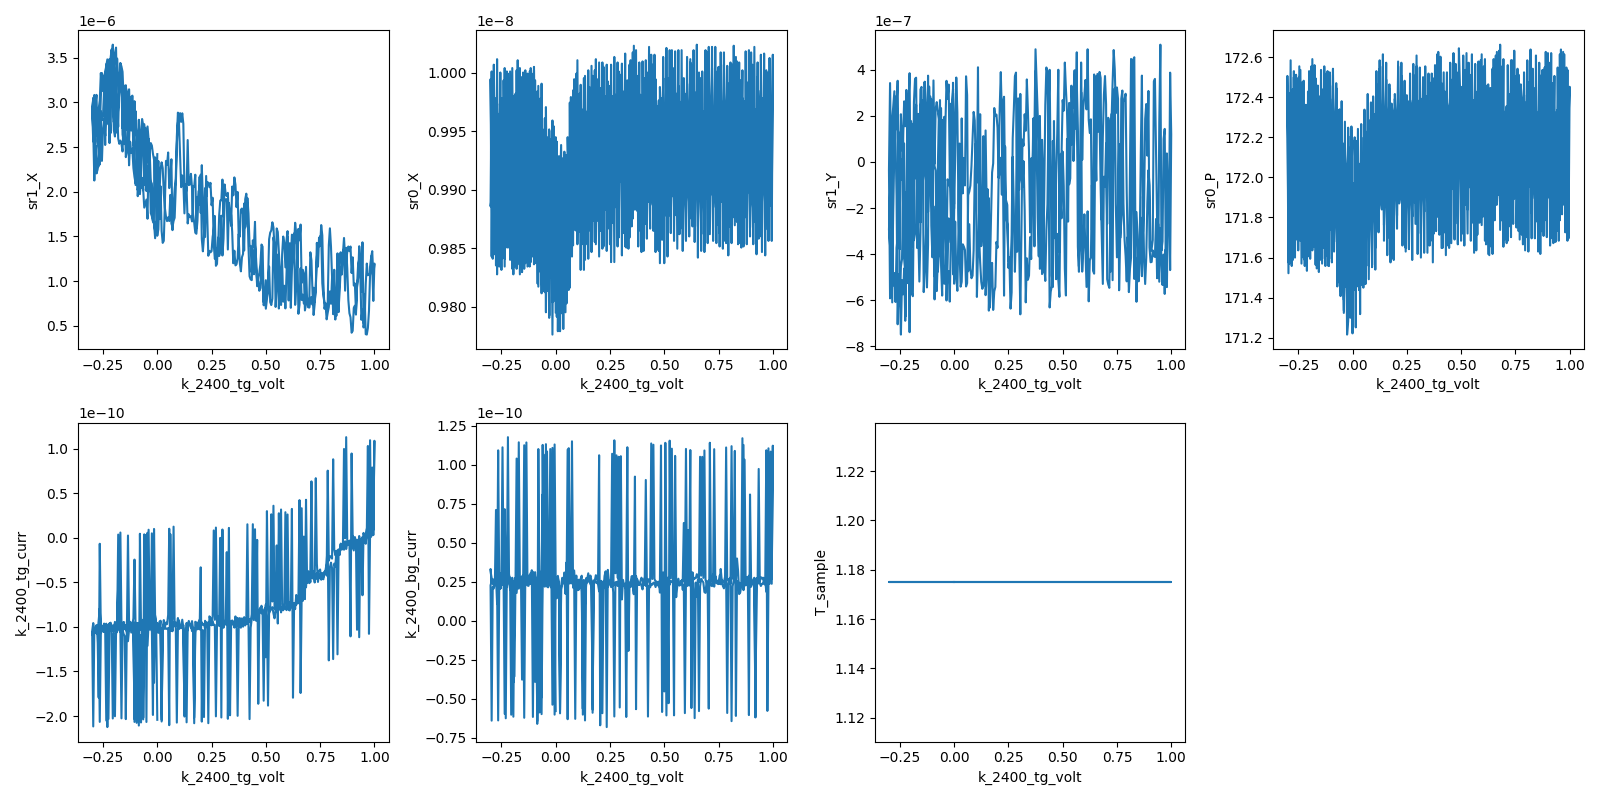

2026-08-23 20:31:18,695 [INFO] Completed in 0h 3m 10s


2026-08-23 20:31:18,696 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\0\data.tsv.gz


run 0: 3.2 min, 0.299 s/pt; sr1 autorange log: [('down', 0.0005), ('down', 0.0002), ('down', 0.0001), ('down', 5e-05), ('down', 2e-05), ('down', 1e-05), ('down', 5e-06)]
end state: V_tg=0.0000 V, V_bg=0.0000 V, T_sample=1.175 K, sr1 sens=5e-06 V


In [18]:
# HERA — gate C: liveness on the provided pair (plan step 0).
# Preconditions (assumed, not set) -> lock-in ranging -> 0D read -> TG sweep at V_bg=0.

# --- preconditions: state this cell inherits
_T, _B, _Vbg, _Vsi = T_sample(), magnet.field(), k_bg.volt(), dc205.voltage()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | "
      f"V_bg={_Vbg:.4f} V (want 0) | V_si={_Vsi:.3f} V (want 0)")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vbg) < 1e-3 and abs(_Vsi) < 0.01, "BG/Si not at 0 V"

# --- lock-in ranging (flagged in the VERIFY markdown; state0 holds the originals for close-out)
for _s in (sr0, sr1):
    _s.time_constant(0.03)
    _s.filter_slope(24)
sr0.sensitivity(0.02)    # 10 nA x 1e6 V/A = 10 mV
sr1.sensitivity(1e-3)    # 100 kOhm full scale at 10 nA; autorange hook below keeps it in band
time.sleep(0.5)

# --- 0D liveness read (printed, not a run)
_I = sr0.X() / meas_config["sr0_gain"]
_P0, _X1, _Y1 = sr0.P(), sr1.X(), sr1.Y()
print(f"liveness: I_drain={_I*1e9:.3f} nA (expect ~10) phase(sr0)={_P0:.1f} deg | "
      f"sr1 X={_X1*1e6:.2f} uV Y={_Y1*1e6:.2f} uV -> Rxx~{(_X1/_I if _I else float('nan')):.1f} Ohm")


class SrAutoRange:
    """run_after hook: keep max(|X|,|Y|) of one SR830 inside [8%, 80%] of its
    sensitivity. Reads the sweep's own row (no extra instrument reads) and only
    talks to the lock-in when a range step is needed."""
    def __init__(self, sr, cols, gain=1.0, lo=1e-6, hi=1.0):
        self.sr, self.cols, self.gain, self.lo, self.hi = sr, cols, gain, lo, hi
        self.sens = sr.sensitivity()
        self.log = []
    def __call__(self, data):
        r = max(abs(float(data[i]) * self.gain) for i in self.cols)
        if r > 0.8 * self.sens and self.sens < self.hi:
            if self.sr.increment_sensitivity():
                self.sens = self.sr.sensitivity(); self.log.append(("up", self.sens))
        elif r < 0.08 * self.sens and self.sens > self.lo:
            if self.sr.decrement_sensitivity():
                self.sens = self.sr.sensitivity(); self.log.append(("down", self.sens))


# --- station: row = [time, V_tg, sr0_X(->A), sr0_P, sr1_X, sr1_Y, k_tg_curr, k_bg_curr, T_sample]
meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = "gate-c-liveness: TG 0->-0.3->1.0->-0.3->0 V @5 mV, BG=0, Si=0, B=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X, meas_config["sr0_gain"]).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("gate-c-liveness")
s.add_comment("TG 0->-0.3->1.0->-0.3->0 V @5mV, delay 0.2 s, tau 30 ms; V_bg=0, V_si=0, B=0; I_bias 10 nA")
ar1 = SrAutoRange(sr1, cols=(4, 5), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_tg.volt, _p)

_up = spoints(-0.3, 1.0, 261)
_vt = np.concatenate([spoints(0.0, -0.3, 61), _up[1:], _up[::-1][1:], spoints(-0.3, 0.0, 61)[1:]])
print(f"sweep: {len(_vt)} pts, V_tg in [{_vt.min():.2f}, {_vt.max():.2f}] V, ends at {_vt[-1]:.2f} V")
_t0 = time.time()
res = s.sweep(k_tg.volt, _vt, delay=0.2)
_dt = time.time() - _t0
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/len(_vt):.3f} s/pt; sr1 autorange log: {ar1.log}")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


## HERA — plan step 1: BG sweep at V_tg = 0 (CNP hunt)

> **20:33** · bg-sweep-1d: BG 0->2.0->-1.3->0 V @10 mV (661 pts), TG=0, Si=0, B=0, base T; tau 100 ms, delay 0.5 s; I\_bias 10 nA · **ETA ~20:41** (≈8 min)

Run 0 (gate C) passed: pair alive at 9.9 nA, no leakage, but |Rxx| only 40–370 Ω over the whole TG box at V_bg = 0 with no CNP peak — the CNP is outside that cut (device looks electron-doped by the R trend). The back gate reaches n ≈ −2e12 cm⁻² at V_bg = −1.3 (geometry prior), so this sweep is the cheap way to find the CNP before spending 30 min on a map. Same fp set, but lock-in X stored raw (mc carries the Ithaco gain — run 0 double-divided) and τ = 100 ms / delay 0.5 s to kill the ripple seen at 30 ms. Timing from run 0: 0.30 s/pt at delay 0.2 → ~0.6 s/pt here, 661 pts. Preconditions: base T, B ≈ 0, V_tg = V_si = 0. Kill: leakage excess > 200 pA on either Keithley, or I_drain collapse.


precheck: T_sample=1.175 K (want 1.0-1.4) | B=0.0063 T (want |B|<0.02) | V_tg=0.0000 V (want 0) | V_si=0.000 V (want 0) | V_bg now 0.0000 V


sr0 sens=0.02 V, sr1 sens=5e-06 V (autorange hook active on sr1)


sweep: 661 pts, V_bg in [-1.30, 2.00] V, ends at 0.00 V
2026-08-23 20:33:28,788 [INFO] Starting sweep with ID 1


2026-08-23 20:33:28,789 [INFO] Minimum duration 0h 5m 30s


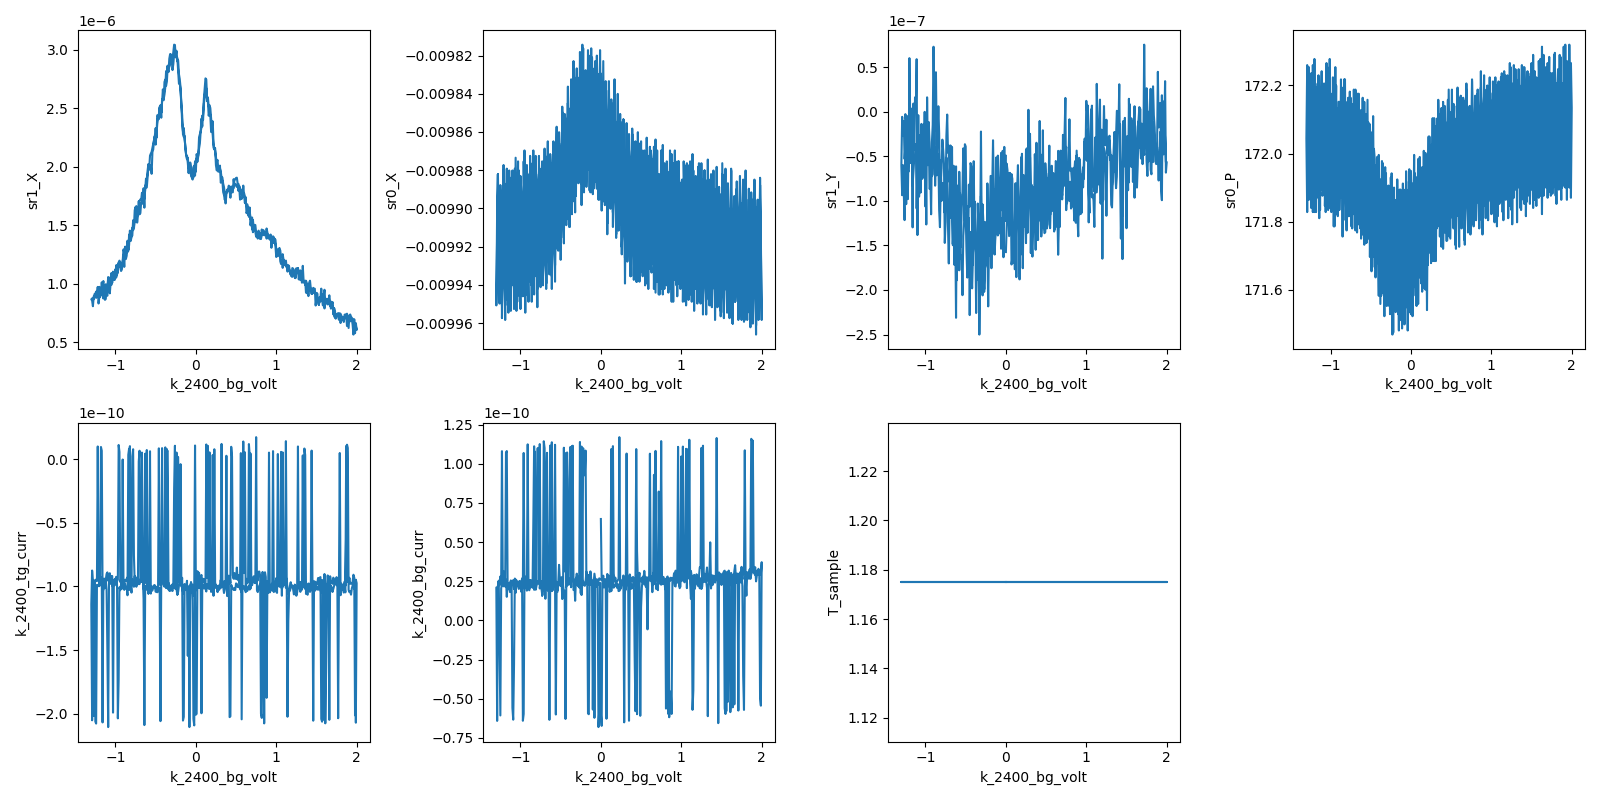

2026-08-23 20:40:04,178 [INFO] Completed in 0h 6m 34s


2026-08-23 20:40:04,179 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\1\data.tsv.gz


run 1: 6.6 min, 0.598 s/pt; sr1 autorange log: []
end state: V_tg=0.0000 V, V_bg=0.0000 V, T_sample=1.175 K, sr1 sens=5e-06 V


In [19]:
# HERA — plan step 1: BG sweep at V_tg = 0 (CNP hunt on the back gate)
_T, _B, _Vtg, _Vsi = T_sample(), magnet.field(), k_tg.volt(), dc205.voltage()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | "
      f"V_tg={_Vtg:.4f} V (want 0) | V_si={_Vsi:.3f} V (want 0) | V_bg now {k_bg.volt():.4f} V")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vtg) < 1e-3 and abs(_Vsi) < 0.01, "TG/Si not at 0 V"

# ranging: tau 100 ms (run 0 showed interference through 30 ms), delay 0.5 s
for _s in (sr0, sr1):
    _s.time_constant(0.1)
    _s.filter_slope(24)
print(f"sr0 sens={sr0.sensitivity()} V, sr1 sens={sr1.sensitivity()} V (autorange hook active on sr1)")
time.sleep(0.5)

# station — lock-in X stored RAW (gain 1); mc['sr0_gain'] carries the Ithaco gain for analysis/hera-watch
meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = "bg-sweep-1d: BG 0->2.0->-1.3->0 V @10 mV, TG=0, Si=0, B=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("bg-sweep-1d")
s.add_comment("BG 0->2.0->-1.3->0 V @10mV (661 pts), delay 0.5 s, tau 100 ms; V_tg=0, V_si=0, B=0; I_bias 10 nA")
ar1 = SrAutoRange(sr1, cols=(4, 5), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_bg.volt, _p)

_vb = np.concatenate([spoints(0.0, 2.0, 201), spoints(2.0, -1.3, 331)[1:], spoints(-1.3, 0.0, 131)[1:]])
print(f"sweep: {len(_vb)} pts, V_bg in [{_vb.min():.2f}, {_vb.max():.2f}] V, ends at {_vb[-1]:.2f} V")
_t0 = time.time()
res = s.sweep(k_bg.volt, _vb, delay=0.5)
_dt = time.time() - _t0
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/len(_vb):.3f} s/pt; sr1 autorange log: {ar1.log}")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


## HERA — plan step 2: coarse full-box gate map at B = 0

> **20:40** · gatemap-coarse: BG slow 2.0->-1.3 V @100 mV (34) x TG fast -0.3->1.0 V @20 mV (66), Si=0, B=0, base T; tau 100 ms, fast\_delay 0.5 s; I\_bias 10 nA · **ETA ~21:08** (≈28 min)

Runs 0/1 put the Rxx maxima inside the box: V_tg ≈ −0.2 V at V_bg = 0 (run 0, weak) and two peaks at V_bg ≈ −0.25 / +0.12 V at V_tg = 0 (run 1, 310 / 275 Ω, reproducible up/down). Peak contrast is only ~3× over the metallic background, so the CNP is very conductive — the D-dependence of that peak is the first stacking discriminator (plan table: ABCA → exponential rise with |D|; ABAB → modest and D-symmetric; ABCB → D-asymmetric). This map covers the whole committed box (TG fast −0.3→1.0 V at 20 mV × BG slow 2.0→−1.3 V at 100 mV, 34 × 66 = 2244 pts) to get the CNP-line slope (→ c_bg/c_tg vs the 0.864 geometry prior), the offsets, and whether the two run-1 peaks are two n = 0 lines (inhomogeneity: parallel) or band features (diverge with D). Priced from run 1: 0.68 s/pt at delay 0.5 s → ~45 s/row + turnaround → ~27 min. Checkpoints: rows 1–3 (rails / leakage / autorange), then at ~row 17. Preconditions: base T, B ≈ 0, Si = 0; gates are set by the sweep itself.


In [20]:
# HERA — plan step 2: coarse full-box gate map at B = 0 (CNP line, D-dependence, offsets)
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | V_si={_Vsi:.3f} V (want 0) | "
      f"gates now V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f}")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
for _s in (sr0, sr1):
    _s.time_constant(0.1)
print(f"sr0 sens={sr0.sensitivity()} V, sr1 sens={sr1.sensitivity()} V, tau={sr1.time_constant()} s")

meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = "gatemap-coarse: TG fast -0.3->1.0 @20 mV (66), BG slow 2.0->-1.3 @100 mV (34), Si=0, B=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("gatemap-coarse")
s.add_comment("megasweep BG slow 2.0->-1.3 V @100mV (34 rows) x TG fast -0.3->1.0 V @20mV (66 pts); "
              "slow_delay 1 s, fast_delay 0.5 s, tau 100 ms; V_si=0, B=0; I_bias 10 nA")
# megasweep row = [time, slow, fast, *followed] -> sr1_X idx 5, sr1_Y idx 6
ar1 = SrAutoRange(sr1, cols=(5, 6), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_tg.volt, _p, k_bg.volt)

_vt = spoints(-0.3, 1.0, 66)
_vb = spoints(2.0, -1.3, 34)
print(f"grid: {len(_vb)} rows x {len(_vt)} pts = {len(_vb)*len(_vt)} pts; est {len(_vb)*(len(_vt)*0.68+3)/60:.0f} min")
_t0 = time.time()
res = s.megasweep(k_bg.volt, _vb, k_tg.volt, _vt, slow_delay=1.0, fast_delay=0.5)
_dt = time.time() - _t0
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/(len(_vb)*len(_vt)):.3f} s/pt incl. turnaround; sr1 autorange log: {ar1.log[-10:]} ({len(ar1.log)} steps)")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


precheck: T_sample=1.175 K (want 1.0-1.4) | B=0.0063 T (want |B|<0.02) | V_si=0.000 V (want 0) | gates now V_tg=0.000 V_bg=0.000


sr0 sens=0.02 V, sr1 sens=5e-06 V, tau=0.1 s
grid: 34 rows x 66 pts = 2244 pts; est 27 min
2026-08-23 20:40:41,448 [INFO] Starting megasweep with ID 2


2026-08-23 20:40:41,449 [INFO] Minimum duration 0h 19m 16s


BrokenPipeError: [WinError 232] The pipe is being closed

## HERA — step 2 relaunch: coarse map with 1D live monitors

> **20:42** · gatemap-coarse (relaunch): BG slow 2.0->-1.3 V @100 mV (34) x TG fast -0.3->1.0 V @20 mV (66), Si=0, B=0, base T; tau 100 ms, fast\_delay 0.5 s; I\_bias 10 nA · **ETA ~21:10** (≈28 min)

Cell 38 (run 2) died at point 3: the live plotter's 2D-mesh subprocess closed its pipe (BrokenPipeError in add_point), aborting the megasweep — a monitor bug, not a device or data problem (3 rows landed, I = 9.93 nA, R = 96 Ω at V_bg = 2.0). Same measurement, same rationale as cell 37, with the seven live plots as 1D lines vs V_tg (the form that worked in runs 0/1). Gates currently sit where the abort left them (V_bg = 2.0, V_tg ≈ −0.26 V); the sweep sets them.

precheck: T_sample=1.175 K (want 1.0-1.4) | B=0.0063 T (want |B|<0.02) | V_si=0.000 V (want 0) | gates now V_tg=-0.260 V_bg=2.000


sr0 sens=0.02 V, sr1 sens=5e-06 V, tau=0.1 s
grid: 34 rows x 66 pts = 2244 pts; est 27 min
2026-08-23 20:42:35,080 [INFO] Starting megasweep with ID 3


2026-08-23 20:42:35,081 [INFO] Minimum duration 0h 19m 16s


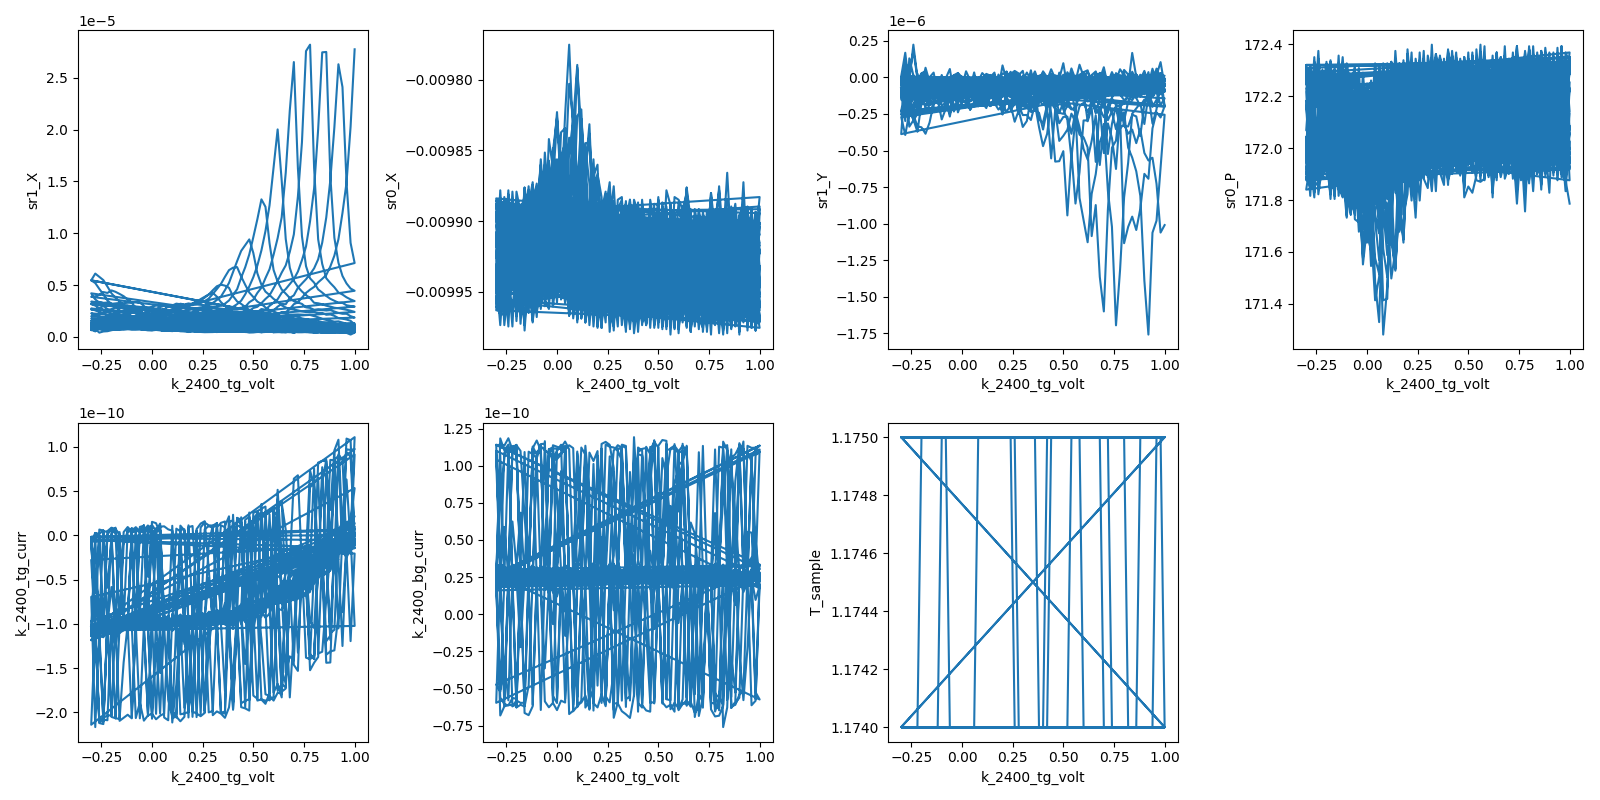

2026-08-23 21:07:23,440 [INFO] Completed in 0h 24m 47s


2026-08-23 21:07:23,441 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\3\data.tsv.gz


run 3: 24.8 min, 0.663 s/pt incl. turnaround; sr1 autorange log: [('down', 5e-06), ('up', 1e-05), ('up', 2e-05), ('up', 5e-05), ('down', 2e-05), ('down', 1e-05), ('down', 5e-06), ('up', 1e-05), ('up', 2e-05), ('up', 5e-05)] (47 steps)
end state: V_tg=1.0000 V, V_bg=-1.3000 V, T_sample=1.174 K, sr1 sens=5e-05 V


In [21]:
# HERA — plan step 2: coarse full-box gate map at B = 0 (CNP line, D-dependence, offsets)
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | V_si={_Vsi:.3f} V (want 0) | "
      f"gates now V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f}")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
for _s in (sr0, sr1):
    _s.time_constant(0.1)
print(f"sr0 sens={sr0.sensitivity()} V, sr1 sens={sr1.sensitivity()} V, tau={sr1.time_constant()} s")

meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = "gatemap-coarse: TG fast -0.3->1.0 @20 mV (66), BG slow 2.0->-1.3 @100 mV (34), Si=0, B=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("gatemap-coarse")
s.add_comment("megasweep BG slow 2.0->-1.3 V @100mV (34 rows) x TG fast -0.3->1.0 V @20mV (66 pts); "
              "slow_delay 1 s, fast_delay 0.5 s, tau 100 ms; V_si=0, B=0; I_bias 10 nA")
# megasweep row = [time, slow, fast, *followed] -> sr1_X idx 5, sr1_Y idx 6
ar1 = SrAutoRange(sr1, cols=(5, 6), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
# live monitor: 1D lines vs V_tg (the 2D-mesh plotter path killed its subprocess at point 3 in run 2 — BrokenPipe)
for _p in (sr1.X, sr0.X, sr1.Y, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_tg.volt, _p)

_vt = spoints(-0.3, 1.0, 66)
_vb = spoints(2.0, -1.3, 34)
print(f"grid: {len(_vb)} rows x {len(_vt)} pts = {len(_vb)*len(_vt)} pts; est {len(_vb)*(len(_vt)*0.68+3)/60:.0f} min")
_t0 = time.time()
res = s.megasweep(k_bg.volt, _vb, k_tg.volt, _vt, slow_delay=1.0, fast_delay=0.5)
_dt = time.time() - _t0
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/(len(_vb)*len(_vt)):.3f} s/pt incl. turnaround; sr1 autorange log: {ar1.log[-10:]} ({len(ar1.log)} steps)")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


## HERA — plan step 3: fine band map along the CNP line

> **21:09** · cnp-band-map: multisweep (V\_bg,V\_tg) 39 rows V\_bg -1.3..0.6 @50 mV x TG +/-0.15 V @5 mV about V\_tg=0.10-0.691\*V\_bg; Si=0, B=0, base T; tau 100 ms, delay 0.5 s · **ETA ~21:37** (≈28 min)

Run 3 fixed the CNP line, V_tg ≈ 0.10 − 0.69·V_bg (c_bg/c_tg ≈ 0.69 vs the 0.86 geometry prior), and showed R_CNP rising from ≈320 Ω (D ≈ 0) to ≈2.8 kΩ and saturating beyond D ≈ +0.25 V/nm — a modest, non-insulating gap opening, Bernal-leaning. Two things the coarse map can't settle: the peak value and width per D at 20 mV TG resolution (the ridge is ~0.1 V wide) and the ±D comparison, whose negative-D rows were pinned at the V_tg = −0.3 edge. This cell rasters a ±0.15 V TG window (5 mV) about the fitted line at 50 mV V_bg rows from −1.3 to +0.6 V as one co-swept multisweep (rows clipped to the box by sanitize_tg_bg), starting from the hole-side end where the gates sit. Yields R_CNP(D), FWHM(D) and the line position to 5 mV over D ≈ −0.12…+0.34 V/nm (geometry scale). Priced from run 3: 0.68 s/pt × ~2300 pts ≈ 27 min. Checkpoints: first 2 rows, then ~row 20. Preconditions: base T, B ≈ 0, Si = 0.

precheck: T_sample=1.174 K (want 1.0-1.4) | B=0.0063 T (want |B|<0.02) | V_si=0.000 V (want 0) | gates now V_tg=1.000 V_bg=-1.300


sr0 sens=0.02 V, sr1 sens=5e-05 V, tau=0.1 s
band map: 39 rows (V_bg -1.30..+0.60), 2199 pts after box clip; V_tg in [-0.300, 1.000]; est 25 min
2026-08-23 21:09:40,116 [INFO] Starting multisweep with ID 4


2026-08-23 21:09:40,117 [INFO] Minimum duration 0h 18m 19s


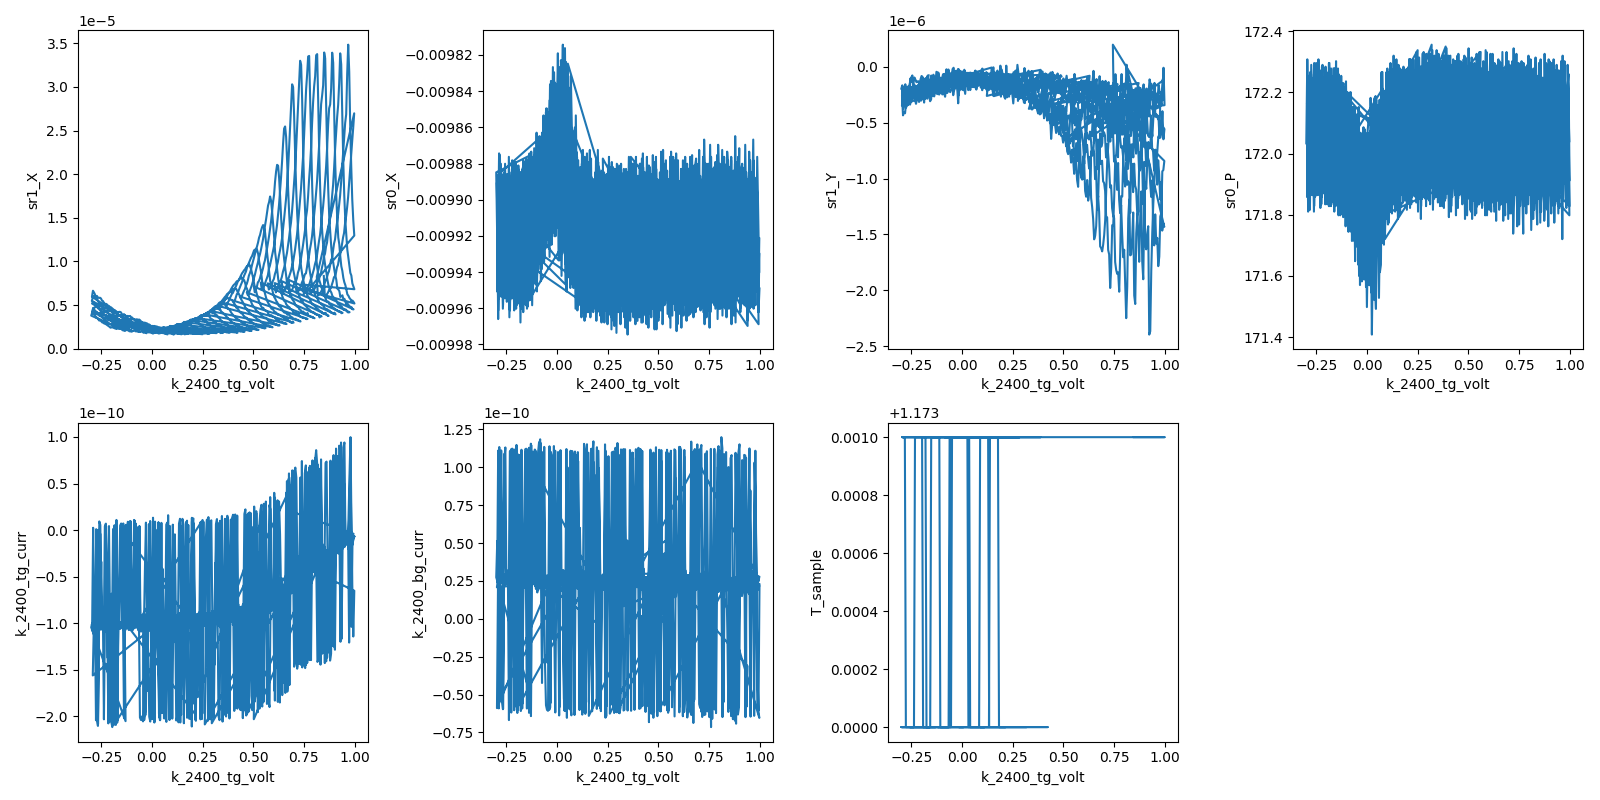

2026-08-23 21:31:47,249 [INFO] Completed in 0h 22m 6s


2026-08-23 21:31:47,250 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\4\data.tsv.gz


run 4: 22.1 min, 0.604 s/pt; sr1 autorange steps: 9 (last [('down', 2e-05), ('up', 5e-05), ('down', 2e-05), ('up', 5e-05), ('down', 2e-05)])
end state: V_tg=-0.1645 V, V_bg=0.6000 V, T_sample=1.173 K, sr1 sens=2e-05 V


In [22]:
# HERA — plan step 3: fine band map along the CNP line (R_CNP(D), peak width, ±D comparison)
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | V_si={_Vsi:.3f} V (want 0) | "
      f"gates now V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f}")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
for _s in (sr0, sr1):
    _s.time_constant(0.1)
print(f"sr0 sens={sr0.sensitivity()} V, sr1 sens={sr1.sensitivity()} V, tau={sr1.time_constant()} s")

# CNP line from run 3 ridge (rows V_bg -0.2..-1.3): V_tg = 0.10 - 0.691 * V_bg
CNP_A, CNP_B = 0.10, -0.691
_vb_rows = np.round(np.arange(-1.3, 0.60 + 1e-9, 0.05), 3)          # slow: hole-side end first (gates sit at V_bg=-1.3, V_tg=1.0)
_dv = np.round(np.arange(-0.15, 0.15 + 1e-9, 0.005), 4)             # fast: TG window about the line, 5 mV
_vt_list, _vb_list = [], []
for _vb in _vb_rows:
    _vt = CNP_A + CNP_B * _vb + _dv
    _vt_ok, _vb_ok = sanitize_tg_bg(_vt, np.full_like(_vt, _vb), tg_lims, bg_lims)
    _vt_list.append(_vt_ok); _vb_list.append(_vb_ok)
_vt_all = np.concatenate(_vt_list); _vb_all = np.concatenate(_vb_list)
_npts = len(_vt_all)
print(f"band map: {len(_vb_rows)} rows (V_bg {_vb_rows[0]:+.2f}..{_vb_rows[-1]:+.2f}), {_npts} pts after box clip; "
      f"V_tg in [{_vt_all.min():.3f}, {_vt_all.max():.3f}]; est {_npts*0.68/60:.0f} min")
assert _vt_all.min() >= TG_MIN and _vt_all.max() <= TG_MAX and _vb_all.min() >= BG_MIN and _vb_all.max() <= BG_MAX

meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = "cnp-band-map: multisweep (V_bg,V_tg) rows V_bg -1.3..0.6 @50 mV, TG +/-0.15 V about V_tg=0.10-0.691*V_bg @5 mV; Si=0, B=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("cnp-band-map")
s.add_comment(f"multisweep [k_bg.volt, k_tg.volt]: {len(_vb_rows)} rows V_bg -1.3..0.6 @50mV x TG window +/-0.15 V @5mV about "
              f"V_tg=0.10-0.691*V_bg (run 3 ridge), box-clipped ({_npts} pts); delay 0.5 s, tau 100 ms; V_si=0, B=0; I_bias 10 nA")
# multisweep row = [time, V_bg, V_tg, *followed] -> sr1_X idx 5, sr1_Y idx 6
ar1 = SrAutoRange(sr1, cols=(5, 6), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_tg.volt, _p)

_t0 = time.time()
res = s.multisweep([k_bg.volt, k_tg.volt], [_vb_all, _vt_all], delay=0.5)
_dt = time.time() - _t0
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/_npts:.3f} s/pt; sr1 autorange steps: {len(ar1.log)} (last {ar1.log[-5:]})")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


## HERA — plan step 4a: Landau fan 0 → 8 T at D ≈ 0 (measure-while-ramping)

> **21:33** · landau-fan-up: B 0->8 T continuous (0.137 T/min) x gate line V\_tg=0.11+0.71\*V\_bg, V\_bg -0.58..+1.25 @15 mV (~127 pts/row, ~41 rows); Si=0, base T; tau 100 ms, delay 0.5 s; I\_bias 10 nA · **ETA ~22:43** (≈1h10m)

Runs 3/4 give the CNP line (V_tg ≈ 0.08 − 0.71·V_bg, c_bg/c_tg ≈ 0.71) and the D ≈ 0 point (0.11, 0.00) where R_CNP is minimal (248 Ω) and symmetric in ±D. The stacking call now needs the Landau-level structure near neutrality (bilayer-like ν = ±4 sectors with crossings for ABAB vs a 16-fold zero-energy manifold, first gaps at ν = ±8, for ABCA) and the absolute density scale (ν-line slopes n = νeB/h, which also calibrates the D axis). Method: the magnet ramps continuously 0 → 8 T at its fixed 0.137 T/min (start_field_ramp, non-blocking) while the gates are co-swept along the constant-D line through the D0 point every row; B is recorded per point, so rows are slanted by ~0.2 T and the analysis bins on measured B — the whole fan fits in the bare ramp time. Price: ~127 pts/row × 0.72 s + flyback ≈ 95 s/row; 8 T / 0.137 T/min = 58 min ramp → 39 rows + 2 rows at 8 T ≈ 65 min. Field stays ≤ 8 T (cap 10 T). Checkpoints: rows 0–2 (rails, autorange, B readback advancing), then ~every 20 min. Interrupting this cell does not stop the magnet (rig card) — it holds at 8 T; recovery is a new field() call. Preconditions: base T, B ≈ 0, PS heater on + output enabled, Si = 0.

In [23]:
# HERA — plan step 4a: Landau fan 0 -> 8 T at D ~ 0, measure-while-ramping
# (magnet ramps continuously at its fixed 0.137 T/min; gates co-swept along the constant-D line each row;
#  B is read per point -> rows are slanted in B, analysis bins on the measured field)
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_st = magnet._status()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | V_si={_Vsi:.3f} V (want 0) | "
      f"PS on={_st['persistent_switch_on']} output={_st['output_enabled']} | gates now V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f}")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 0.02, "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
assert _st["persistent_switch_on"] and _st["output_enabled"], "magnet PS/output not ready"
for _s in (sr0, sr1):
    _s.time_constant(0.1)

# constant-D line through the CNP-ridge R minimum (run 3/4): slope dV_tg/dV_bg = c_bg/c_tg = CNP_RATIO
CNP_RATIO = 0.71                       # run 4 ridge refit (hole-side rows), c_bg/c_tg
VT0, VB0 = 0.11, 0.00                  # run 4: R_CNP minimum (248 Ω) on the ridge = D ~ 0 point
_vb = np.round(np.arange(VB0 - 0.70, VB0 + 1.25 + 1e-9, 0.015), 4)
_vt = VT0 + CNP_RATIO * (_vb - VB0)
_vt, _vb = sanitize_tg_bg(_vt, _vb, tg_lims, bg_lims)
assert _vt.min() >= TG_MIN and _vt.max() <= TG_MAX and _vb.min() >= BG_MIN and _vb.max() <= BG_MAX
B_TARGET = 8.0
_row_s = len(_vt) * 0.72 + 4.0                                   # per-row estimate (run 4: 0.68 s/pt + field read) + flyback
N_ROWS = int(np.ceil(B_TARGET / magnet.slew_T_per_s / _row_s)) + 2   # rows to cover the ramp, +2 rows at 8 T
print(f"fan: {N_ROWS} rows x {len(_vt)} pts (V_bg {_vb[0]:+.3f}..{_vb[-1]:+.3f}, V_tg {_vt[0]:+.3f}..{_vt[-1]:+.3f}); "
      f"~{_row_s:.0f} s/row, ramp {B_TARGET/magnet.slew_T_per_s/60:.0f} min, est total {N_ROWS*_row_s/60:.0f} min")

fan_row = qcodes.Parameter("fan_row", set_cmd=None, get_cmd=None, initial_value=0)
meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = f"landau-fan-up: B 0->8 T continuous ramp, gates along D~0 line through ({VT0:+.3f},{VB0:+.3f}), {N_ROWS} rows; Si=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(magnet.field).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("landau-fan-up")
s.add_comment(f"multimegasweep fan_row x [k_tg.volt,k_bg.volt] along V_tg={VT0:+.3f}+{CNP_RATIO}*(V_bg-({VB0:+.3f})), "
              f"V_bg {_vb[0]:+.3f}..{_vb[-1]:+.3f} @15mV ({len(_vt)} pts); magnet start_field_ramp(8.0) then {N_ROWS} rows, "
              f"B read per point; fast_delay 0.5 s, tau 100 ms; V_si=0; I_bias 10 nA")
# multimegasweep row = [time, fan_row, V_tg, V_bg, *followed] -> sr1_X idx 6, sr1_Y idx 7
ar1 = SrAutoRange(sr1, cols=(6, 7), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, magnet.field, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_bg.volt, _p)

# park the gates at the row start before the ramp begins (paced by volt.step)
k_bg.volt(_vb[0]); k_tg.volt(_vt[0])
time.sleep(1.0)
magnet.start_field_ramp(B_TARGET)
print(f"ramp started at {time.strftime('%H:%M:%S')}; B={magnet.field():.4f} T, is_ramping={magnet.is_ramping()}")
_t0 = time.time()
try:
    res = s.multimegasweep([fan_row], [np.arange(N_ROWS)], [k_tg.volt, k_bg.volt], [_vt, _vb],
                           slow_delay=0.0, fast_delay=0.5, init_delay=False)
finally:
    _dt = time.time() - _t0
    print(f"sweep ended after {_dt/60:.1f} min; B={magnet.field():.4f} T, is_ramping={magnet.is_ramping()}")
magnet.wait_for_ramp()
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/(N_ROWS*len(_vt)):.3f} s/pt; B={magnet.field():.4f} T; sr1 autorange steps {len(ar1.log)}")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


precheck: T_sample=1.173 K (want 1.0-1.4) | B=0.0063 T (want |B|<0.02) | V_si=0.000 V (want 0) | PS on=True output=True | gates now V_tg=-0.165 V_bg=0.600
fan: 41 rows x 122 pts (V_bg -0.565..+1.250, V_tg -0.291..+0.997); ~92 s/row, ramp 58 min, est total 63 min


ramp started at 21:33:42; B=0.0063 T, is_ramping=True
2026-08-23 21:33:42,664 [INFO] Starting multimegasweep with ID 5


2026-08-23 21:33:42,664 [INFO] Minimum duration 0h 41m 41s


sweep ended after 0.0 min; B=0.0088 T, is_ramping=True


TypeError: Object of type int64 is not JSON serializable

## HERA — step 4a relaunch: fan with float row setpoints (magnet already ramping)

> **21:38** · landau-fan-up (relaunch, ramp in progress): B ~0.7->8 T continuous x gate line V\_tg=0.11+0.71\*V\_bg, V\_bg -0.58..+1.25 @15 mV; Si=0, base T; tau 100 ms, delay 0.5 s · **ETA ~22:43** (≈1h5m)

Cell 44 failed at the writer's metadata dump: the dummy slow axis was an int64 , not JSON-serializable (run 5 is an empty stub). By then  had been issued, so the magnet is ramping toward 8 T since ~21:33 (0.137 T/min). Rather than pay 6 min to return to zero, this relaunch rides the ramp in progress: precheck accepts |B| < 1.5 T, the row count is sized on the remaining field, and  is re-issued (same target, harmless). The lost 0 → ~0.7 T is not where the ν-lines are resolvable. Same line, same pacing, same checkpoints as cell 43.

precheck: T_sample=1.178 K (want 1.0-1.4) | B=0.6087 T (want |B|<0.02) | V_si=0.000 V (want 0) | PS on=True output=True | gates now V_tg=-0.291 V_bg=-0.565
fan: 38 rows x 122 pts (V_bg -0.565..+1.250, V_tg -0.291..+0.997); ~92 s/row, ramp 58 min, est total 58 min


ramp started at 21:38:07; B=0.6121 T, is_ramping=True
2026-08-23 21:38:07,970 [INFO] Starting multimegasweep with ID 6


2026-08-23 21:38:07,971 [INFO] Minimum duration 0h 38m 38s


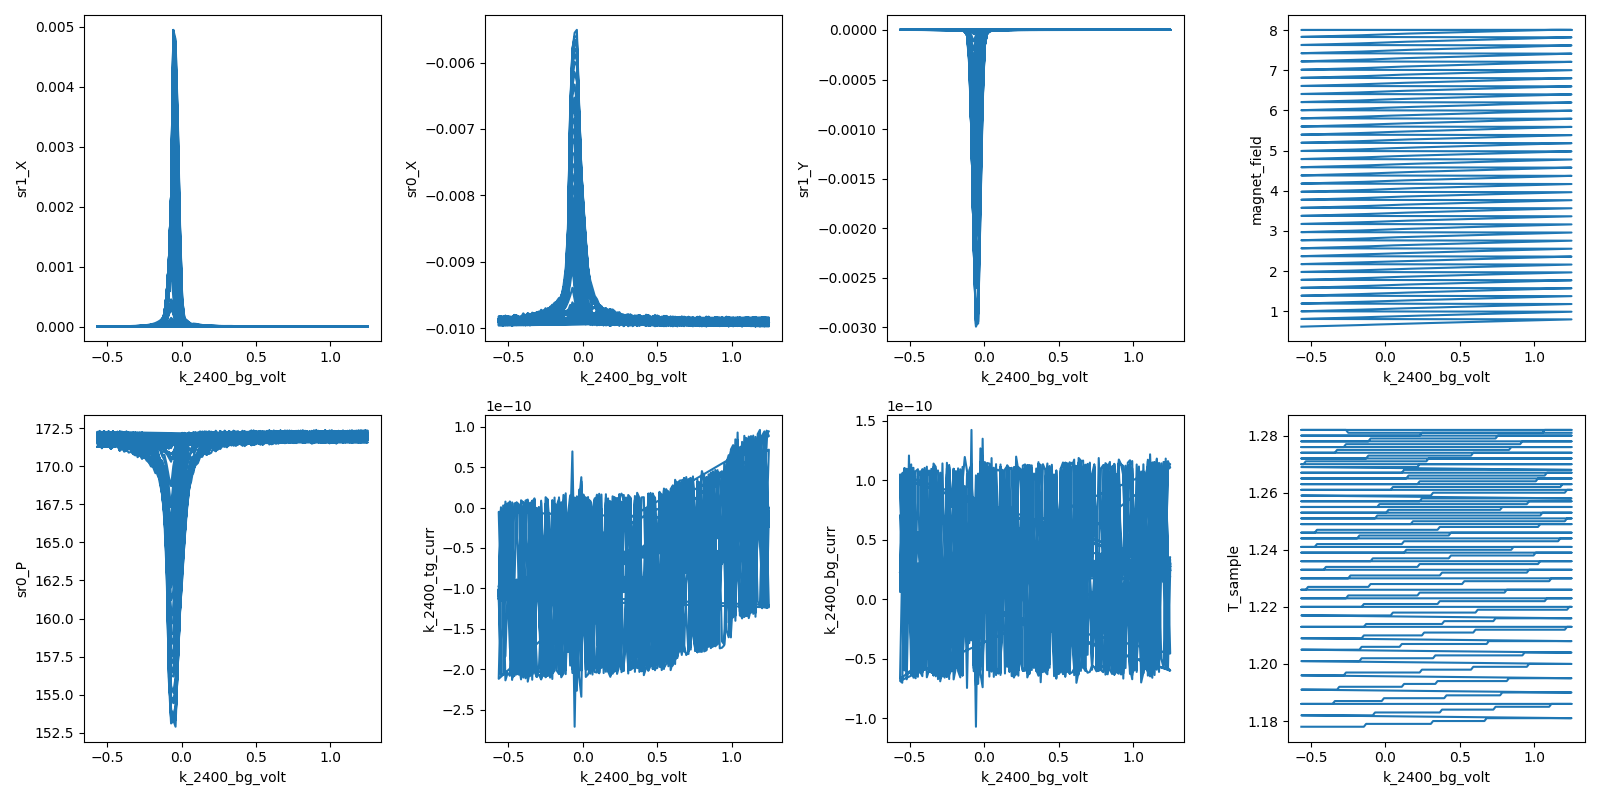

2026-08-23 22:33:30,938 [INFO] Completed in 0h 55m 22s


2026-08-23 22:33:30,938 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\6\data.tsv.gz


sweep ended after 55.4 min; B=8.0063 T, is_ramping=False


run 6: 55.4 min, 0.717 s/pt; B=8.0063 T; sr1 autorange steps 857
end state: V_tg=0.9975 V, V_bg=1.2500 V, T_sample=1.281 K, sr1 sens=1e-05 V


In [24]:
# HERA — plan step 4a: Landau fan 0 -> 8 T at D ~ 0, measure-while-ramping
# (magnet ramps continuously at its fixed 0.137 T/min; gates co-swept along the constant-D line each row;
#  B is read per point -> rows are slanted in B, analysis bins on the measured field)
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_st = magnet._status()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.4) | B={_B:.4f} T (want |B|<0.02) | V_si={_Vsi:.3f} V (want 0) | "
      f"PS on={_st['persistent_switch_on']} output={_st['output_enabled']} | gates now V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f}")
assert 1.0 <= _T <= 1.4, "T_sample out of base window"
assert abs(_B) < 1.5, "magnet not near zero (relaunch: ramp already in progress from the first attempt, cell 42)"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
assert _st["persistent_switch_on"] and _st["output_enabled"], "magnet PS/output not ready"
for _s in (sr0, sr1):
    _s.time_constant(0.1)

# constant-D line through the CNP-ridge R minimum (run 3/4): slope dV_tg/dV_bg = c_bg/c_tg = CNP_RATIO
CNP_RATIO = 0.71                       # run 4 ridge refit (hole-side rows), c_bg/c_tg
VT0, VB0 = 0.11, 0.00                  # run 4: R_CNP minimum (248 Ω) on the ridge = D ~ 0 point
_vb = np.round(np.arange(VB0 - 0.70, VB0 + 1.25 + 1e-9, 0.015), 4)
_vt = VT0 + CNP_RATIO * (_vb - VB0)
_vt, _vb = sanitize_tg_bg(_vt, _vb, tg_lims, bg_lims)
assert _vt.min() >= TG_MIN and _vt.max() <= TG_MAX and _vb.min() >= BG_MIN and _vb.max() <= BG_MAX
B_TARGET = 8.0
_row_s = len(_vt) * 0.72 + 4.0                                   # per-row estimate (run 4: 0.68 s/pt + field read) + flyback
N_ROWS = int(np.ceil((B_TARGET - _B) / magnet.slew_T_per_s / _row_s)) + 2   # rows to cover the remaining ramp, +2 rows at 8 T
print(f"fan: {N_ROWS} rows x {len(_vt)} pts (V_bg {_vb[0]:+.3f}..{_vb[-1]:+.3f}, V_tg {_vt[0]:+.3f}..{_vt[-1]:+.3f}); "
      f"~{_row_s:.0f} s/row, ramp {B_TARGET/magnet.slew_T_per_s/60:.0f} min, est total {N_ROWS*_row_s/60:.0f} min")

fan_row = qcodes.Parameter("fan_row", set_cmd=None, get_cmd=None, initial_value=0)
meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = f"landau-fan-up: B 0->8 T continuous ramp, gates along D~0 line through ({VT0:+.3f},{VB0:+.3f}), {N_ROWS} rows; Si=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(magnet.field).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("landau-fan-up")
s.add_comment(f"multimegasweep fan_row x [k_tg.volt,k_bg.volt] along V_tg={VT0:+.3f}+{CNP_RATIO}*(V_bg-({VB0:+.3f})), "
              f"V_bg {_vb[0]:+.3f}..{_vb[-1]:+.3f} @15mV ({len(_vt)} pts); magnet start_field_ramp(8.0) then {N_ROWS} rows, "
              f"B read per point; fast_delay 0.5 s, tau 100 ms; V_si=0; I_bias 10 nA")
# multimegasweep row = [time, fan_row, V_tg, V_bg, *followed] -> sr1_X idx 6, sr1_Y idx 7
ar1 = SrAutoRange(sr1, cols=(6, 7), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, magnet.field, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_bg.volt, _p)

# park the gates at the row start before the ramp begins (paced by volt.step)
k_bg.volt(_vb[0]); k_tg.volt(_vt[0])
time.sleep(1.0)
magnet.start_field_ramp(B_TARGET)
print(f"ramp started at {time.strftime('%H:%M:%S')}; B={magnet.field():.4f} T, is_ramping={magnet.is_ramping()}")
_t0 = time.time()
try:
    res = s.multimegasweep([fan_row], [np.arange(N_ROWS, dtype=float)], [k_tg.volt, k_bg.volt], [_vt, _vb],   # float rows: int64 setpoints broke the metadata JSON (run 5)
                           slow_delay=0.0, fast_delay=0.5, init_delay=False)
finally:
    _dt = time.time() - _t0
    print(f"sweep ended after {_dt/60:.1f} min; B={magnet.field():.4f} T, is_ramping={magnet.is_ramping()}")
magnet.wait_for_ramp()
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/(N_ROWS*len(_vt)):.3f} s/pt; B={magnet.field():.4f} T; sr1 autorange steps {len(ar1.log)}")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


## HERA — plan step 4b: Landau fan 8 → 0 T at D−D0 ≈ +0.20 V/nm (plateau knee)

> **00:37** · landau-fan-down: B 8->0 T continuous x gate line V\_tg=0.657+0.71\*(V\_bg+0.85), V\_bg -1.3..-0.30 @7.5 mV; Si=0, base T; tau 100 ms, delay 0.5 s; I\_bias 10 nA · **ETA ~01:42** (≈1h5m)

Run 6 (up-fan at D ≈ 0) is complete: 38 rows to 8.006 T; the ν = 0 state grows from 2 kΩ at 0.8 T to ≈495 kΩ at 8 T. Per the plan (never re-traverse), the way down measures the second fan at finite D — the knee of the R_CNP(D) plateau (run 4: V_bg = −0.85, V_tg = 0.657, R = 2.6 kΩ, D−D0 ≈ +0.20 V/nm). This tests the LL structure of the gapped state (Bernal: layer-polarized bilayer-sector LLs with crossings; ABCA would show the split 16-fold manifold) and whether the plateau is a parallel path (its own LL signature). Same measure-while-ramping method, n span ±1.1e12 cm⁻² about the CNP at 7.5 mV steps (~140 pts/row), ~37 rows in the 58-min descent. Magnet holds at 8 T now; T_sample 1.28 K (mild ramp heating, within window). Checkpoints: rows 0–2, then ~every 20 min.

precheck: T_sample=1.277 K (want 1.0-1.5) | B=8.0063 T (want ~8, not ramping) | is_ramping=False | V_si=0.000 V (want 0) | PS on=True output=True | gates now V_tg=0.998 V_bg=1.250
fan: 40 rows x 125 pts (V_bg -1.298..-0.367, V_tg +0.339..+1.000); ~94 s/row, ramp 58 min, est total 63 min


ramp started at 00:38:03; B=8.0063 T, is_ramping=True
2026-08-24 00:38:03,365 [INFO] Starting multimegasweep with ID 7


2026-08-24 00:38:03,366 [INFO] Minimum duration 0h 41m 40s


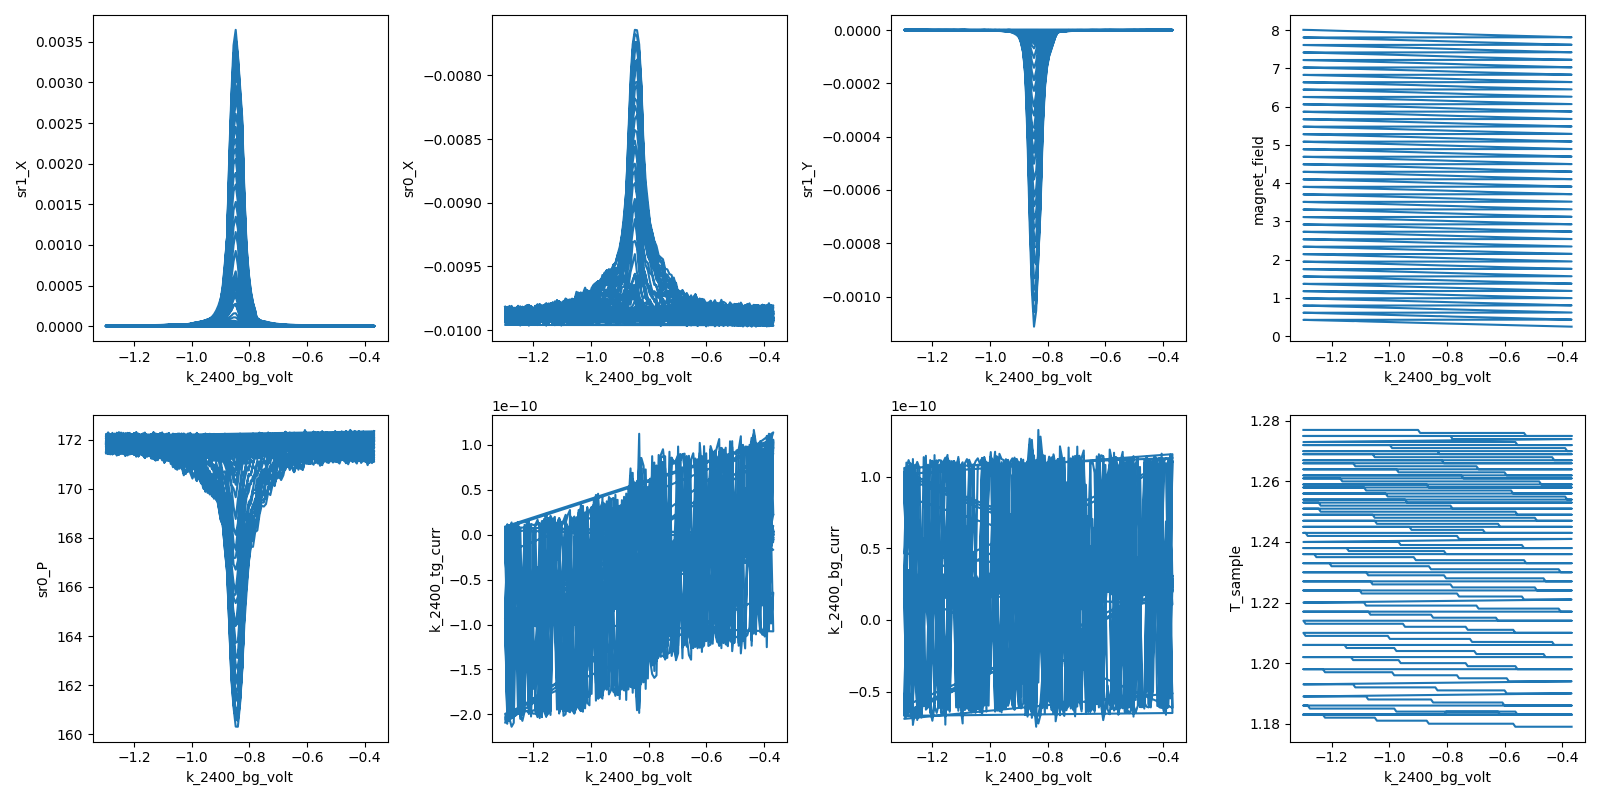

2026-08-24 01:34:32,967 [INFO] Completed in 0h 56m 28s


2026-08-24 01:34:32,968 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\7\data.tsv.gz


sweep ended after 56.5 min; B=0.2428 T, is_ramping=True


run 7: 56.5 min, 0.678 s/pt; B=0.0028 T; sr1 autorange steps 770
end state: V_tg=0.9995 V, V_bg=-0.3675 V, T_sample=1.179 K, sr1 sens=1e-05 V


In [25]:
# HERA — plan step 4b: Landau fan 8 -> 0 T at finite D (plateau knee), measure-while-ramping down
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
_st = magnet._status()
print(f"precheck: T_sample={_T:.3f} K (want 1.0-1.5) | B={_B:.4f} T (want ~8, not ramping) | is_ramping={magnet.is_ramping()} | "
      f"V_si={_Vsi:.3f} V (want 0) | PS on={_st['persistent_switch_on']} output={_st['output_enabled']} | gates now V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f}")
assert 1.0 <= _T <= 1.5, "T_sample out of base window"
assert 7.9 <= _B <= 8.1 and not magnet.is_ramping(), "magnet not holding at 8 T"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
assert _st["persistent_switch_on"] and _st["output_enabled"], "magnet PS/output not ready"
for _s in (sr0, sr1):
    _s.time_constant(0.1)

# constant-D line through the run-4 CNP point at V_bg = -0.85 (R_CNP 2.6 kOhm, D-D0 ~ +0.20 V/nm: knee of the plateau)
CNP_RATIO = 0.71
VT0, VB0 = 0.657, -0.85
_vb = np.round(np.arange(VB0 - 0.50, VB0 + 0.55 + 1e-9, 0.0075), 4)
_vt = VT0 + CNP_RATIO * (_vb - VB0)
_vt, _vb = sanitize_tg_bg(_vt, _vb, tg_lims, bg_lims)
assert _vt.min() >= TG_MIN and _vt.max() <= TG_MAX and _vb.min() >= BG_MIN and _vb.max() <= BG_MAX
B_TARGET = 0.0
_row_s = len(_vt) * 0.72 + 4.0
N_ROWS = int(np.ceil((_B - B_TARGET) / magnet.slew_T_per_s / _row_s)) + 2
print(f"fan: {N_ROWS} rows x {len(_vt)} pts (V_bg {_vb[0]:+.3f}..{_vb[-1]:+.3f}, V_tg {_vt[0]:+.3f}..{_vt[-1]:+.3f}); "
      f"~{_row_s:.0f} s/row, ramp {(_B-B_TARGET)/magnet.slew_T_per_s/60:.0f} min, est total {N_ROWS*_row_s/60:.0f} min")

fan_row = qcodes.Parameter("fan_row", set_cmd=None, get_cmd=None, initial_value=0)
meas_config["sample_temperature:"] = T_sample()
meas_config["Si (V)"] = dc205.voltage()
meas_config["comments"] = f"landau-fan-down: B 8->0 T continuous ramp, gates along D-D0~+0.20 line through ({VT0:+.3f},{VB0:+.3f}), {N_ROWS} rows; Si=0, base T"
s = sweep.AsyncStation(meas_config)
s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(magnet.field).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample)
s.add_comment("landau-fan-down")
s.add_comment(f"multimegasweep fan_row x [k_tg.volt,k_bg.volt] along V_tg={VT0:+.3f}+{CNP_RATIO}*(V_bg-({VB0:+.3f})), "
              f"V_bg {_vb[0]:+.3f}..{_vb[-1]:+.3f} @7.5mV ({len(_vt)} pts); magnet start_field_ramp(0.0) from 8 T then {N_ROWS} rows, "
              f"B read per point; fast_delay 0.5 s, tau 100 ms; V_si=0; I_bias 10 nA")
ar1 = SrAutoRange(sr1, cols=(6, 7), gain=1.0, lo=1e-6, hi=0.5)
s.register_run_after(ar1, args=())
for _p in (sr1.X, sr0.X, sr1.Y, magnet.field, sr0.P, k_tg.curr, k_bg.curr, T_sample):
    s.plot(k_bg.volt, _p)

k_bg.volt(_vb[0]); k_tg.volt(_vt[0])
time.sleep(1.0)
magnet.start_field_ramp(B_TARGET)
print(f"ramp started at {time.strftime('%H:%M:%S')}; B={magnet.field():.4f} T, is_ramping={magnet.is_ramping()}")
_t0 = time.time()
try:
    res = s.multimegasweep([fan_row], [np.arange(N_ROWS, dtype=float)], [k_tg.volt, k_bg.volt], [_vt, _vb],
                           slow_delay=0.0, fast_delay=0.5, init_delay=False)
finally:
    _dt = time.time() - _t0
    print(f"sweep ended after {_dt/60:.1f} min; B={magnet.field():.4f} T, is_ramping={magnet.is_ramping()}")
magnet.wait_for_ramp()
print(f"run {res.id}: {_dt/60:.1f} min, {_dt/(N_ROWS*len(_vt)):.3f} s/pt; B={magnet.field():.4f} T; sr1 autorange steps {len(ar1.log)}")
print(f"end state: V_tg={k_tg.volt():.4f} V, V_bg={k_bg.volt():.4f} V, T_sample={T_sample():.3f} K, sr1 sens={sr1.sensitivity()} V")


## HERA — plan step 5: temperature ladder of R_CNP at five D values (B = 0)

> **01:36** · cnp-t-ladder: T base,2,3,4.5,6.5,9,13,18,25,35,50 K (set\_both ratio 0.95, hover acceptance); per T one multisweep over 5 CNP windows (D-D0 -0.11,0,+0.10,+0.19,+0.28), 155 pts; B=0, Si=0; tau 100 ms · **ETA ~02:56** (≈1h20m)

Both fans are in (runs 6/7): Bernal-consistent LL structure at D ≈ 0 and at the plateau knee. The last discriminator is the activation behavior of the gapped state: ABCA's D-induced gap would be tens of meV (R collapsing exponentially with T over decades); a Bernal 4L gap is meV-scale; and the B = 0 plateau's nature (activated gap vs parallel-path shunt) shows up directly in whether R_CNP(T) is activated or flat. This cell steps T = base, 2, 3, 4.5, 6.5, 9, 13, 18, 25, 35, 50 K via heater.set_both(T, ratio=0.95) (T cap 100 K committed), accepts each point on stability (rig-card hover acceptance — 90 s minimum, then a 60 s window stable to 3 %), and at each T runs one multisweep over five ±75 mV TG windows centred on the run-4 CNP points at D−D0 ≈ −0.11, 0, +0.10, +0.19, +0.28 V/nm (~2 min per run, one run dir per T). Priced: 11 points × (~2 min sweep + 2–5 min settle) ≈ 60–80 min ascending. Heaters off at the end; descent to base is passive (τ ≈ 27 min, rig card) and runs during analysis/close-out. All dwells are interruptible_sleep. Preconditions: B ≈ 0 and not ramping (run 7 ended at 0.003 T), Si = 0, heaters currently off.

precheck: T_sample=1.179 K (want base 1.0-1.5) | B=0.0063 T (want |B|<0.02, not ramping: True) | V_si=0.000 V (want 0) | heater ranges 0/0 (want 0/0) | T_vap=0.957 K
ladder: 11 T points, 145 pts per run (~1.6 min each)
[01:36:42] T set None -> T_sample 1.179 K (stable=True); T_vap 0.957 K; ranges 0/0


2026-08-24 01:36:42,460 [INFO] Starting multisweep with ID 8


2026-08-24 01:36:42,461 [INFO] Minimum duration 0h 1m 12s


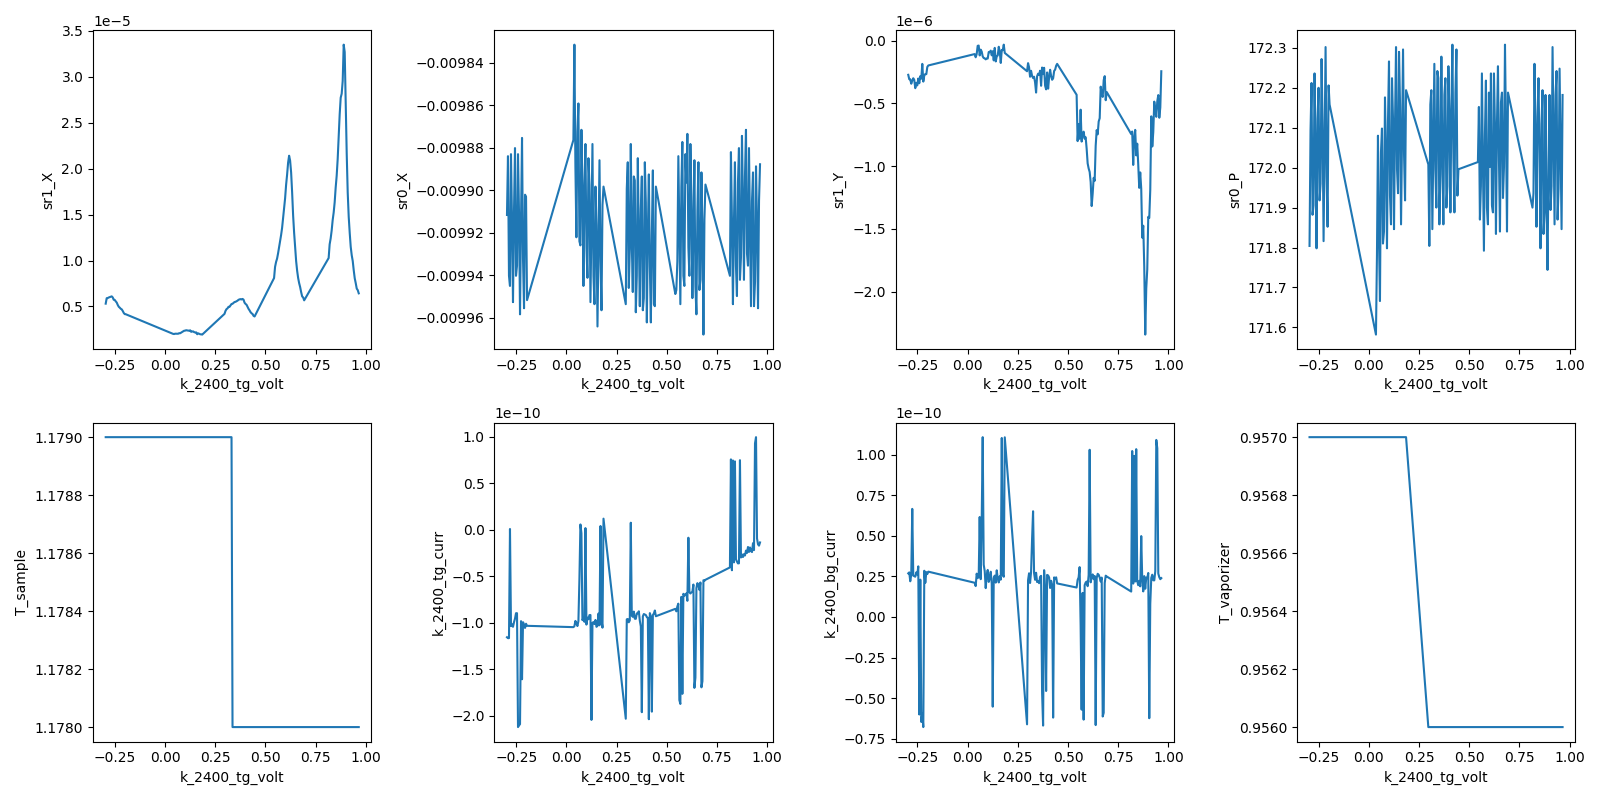

2026-08-24 01:38:14,947 [INFO] Completed in 0h 1m 31s


2026-08-24 01:38:14,948 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\8\data.tsv.gz


   run 8 done; T_sample now 1.178 K


[01:40:34] T set 2.0 -> T_sample 2.000 K (stable=True); T_vap 1.668 K; ranges 1/1
2026-08-24 01:40:35,000 [INFO] Starting multisweep with ID 9


2026-08-24 01:40:35,000 [INFO] Minimum duration 0h 1m 12s


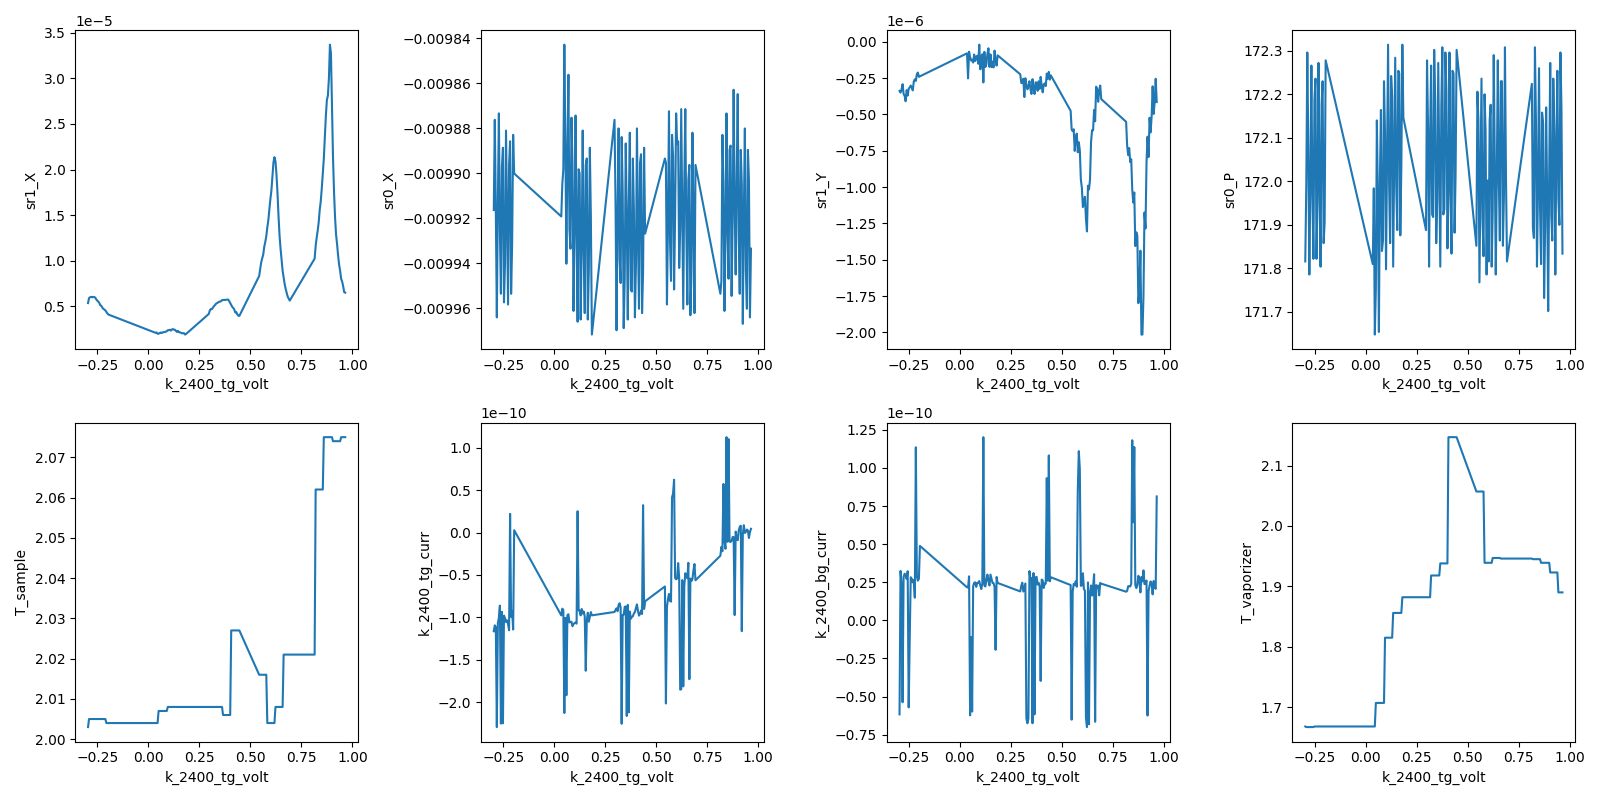

2026-08-24 01:42:08,718 [INFO] Completed in 0h 1m 32s


2026-08-24 01:42:08,719 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\9\data.tsv.gz


   run 9 done; T_sample now 2.075 K


[01:44:28] T set 3.0 -> T_sample 3.171 K (stable=True); T_vap 2.842 K; ranges 1/1
2026-08-24 01:44:28,774 [INFO] Starting multisweep with ID 10


2026-08-24 01:44:28,775 [INFO] Minimum duration 0h 1m 12s


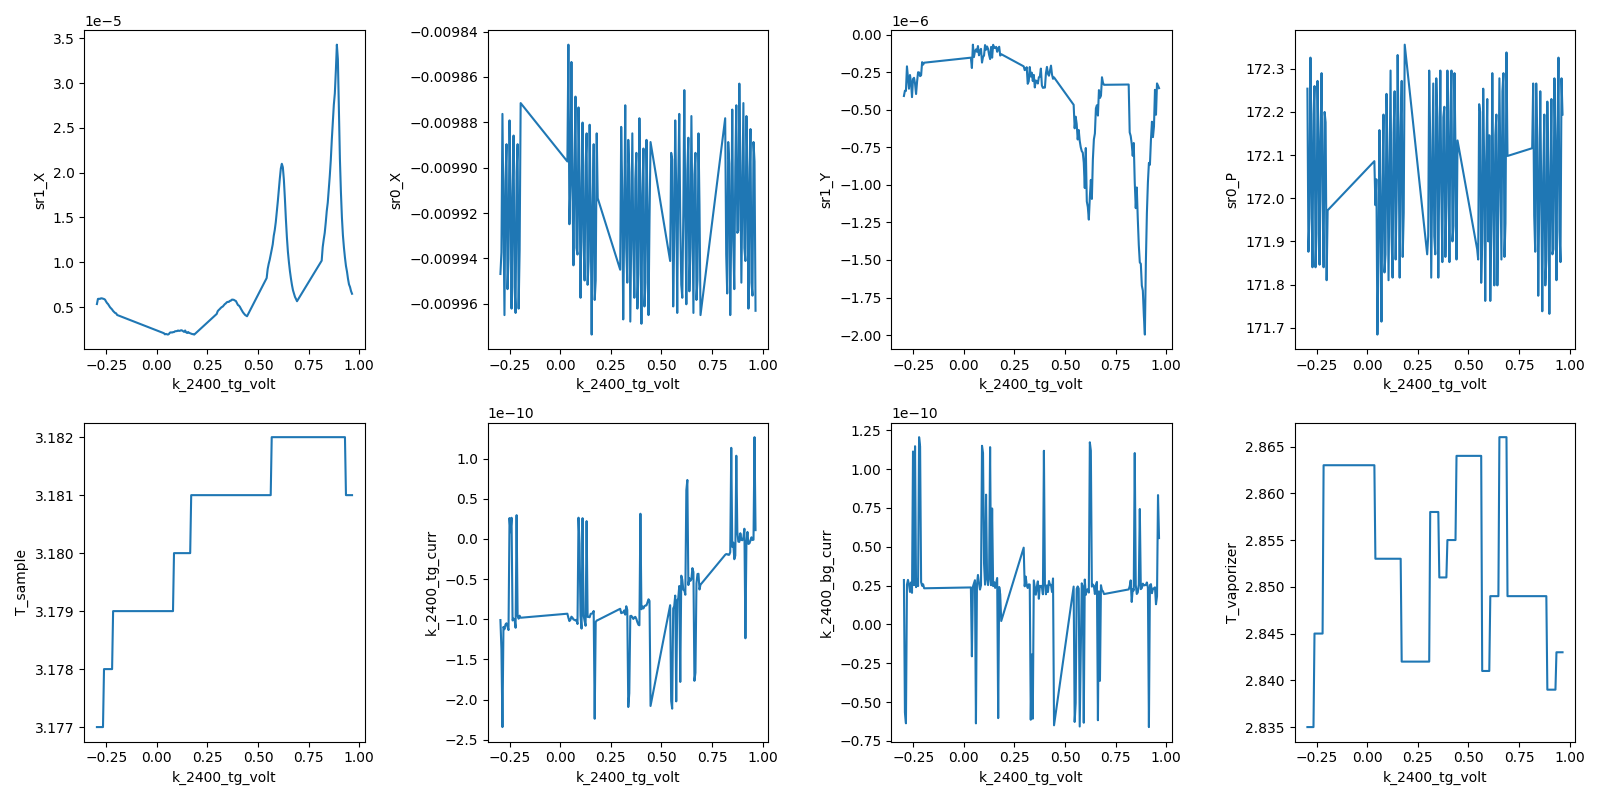

2026-08-24 01:46:02,408 [INFO] Completed in 0h 1m 32s


2026-08-24 01:46:02,409 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\10\data.tsv.gz


   run 10 done; T_sample now 3.181 K


[01:48:22] T set 4.5 -> T_sample 4.635 K (stable=True); T_vap 4.286 K; ranges 1/1
2026-08-24 01:48:22,467 [INFO] Starting multisweep with ID 11


2026-08-24 01:48:22,468 [INFO] Minimum duration 0h 1m 12s


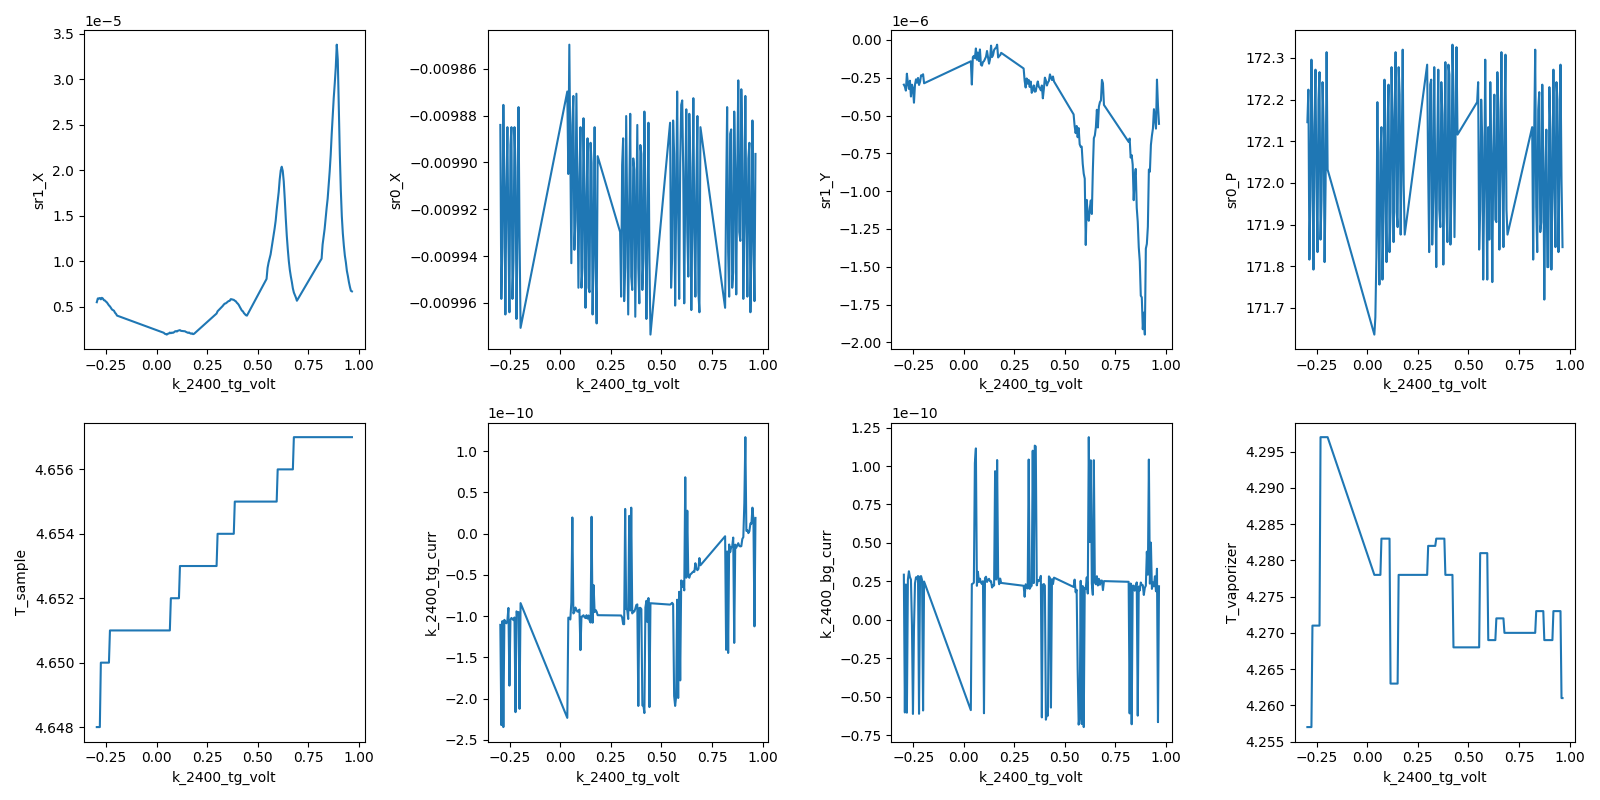

2026-08-24 01:49:56,436 [INFO] Completed in 0h 1m 33s


2026-08-24 01:49:56,437 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\11\data.tsv.gz


   run 11 done; T_sample now 4.657 K


[01:52:16] T set 6.5 -> T_sample 6.567 K (stable=True); T_vap 6.174 K; ranges 1/1
2026-08-24 01:52:16,510 [INFO] Starting multisweep with ID 12


2026-08-24 01:52:16,511 [INFO] Minimum duration 0h 1m 12s


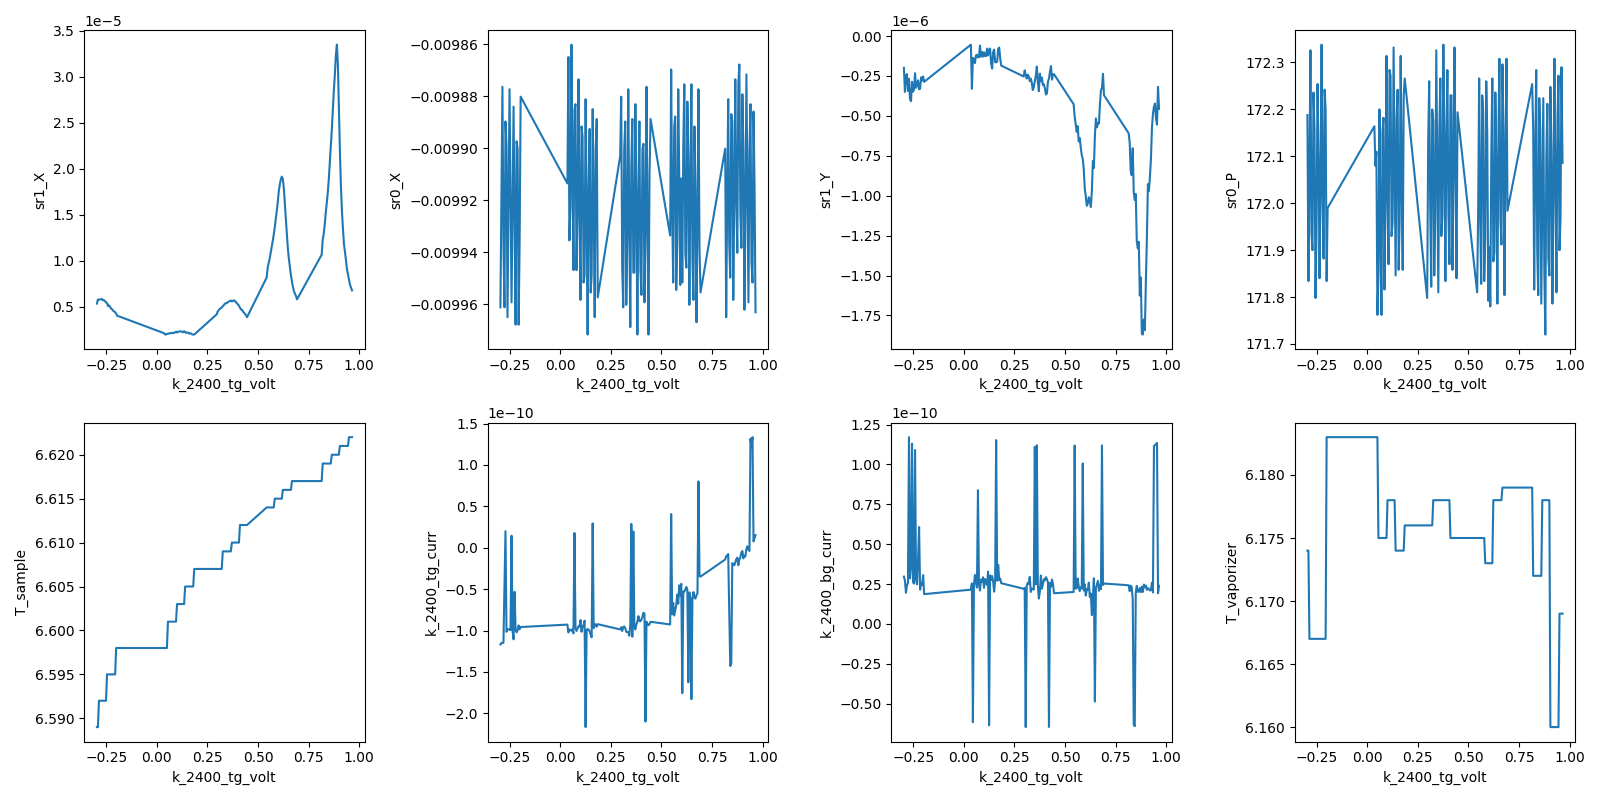

2026-08-24 01:53:50,160 [INFO] Completed in 0h 1m 32s


2026-08-24 01:53:50,161 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\12\data.tsv.gz


   run 12 done; T_sample now 6.622 K


[01:56:10] T set 9.0 -> T_sample 9.009 K (stable=True); T_vap 8.554 K; ranges 1/1
2026-08-24 01:56:10,203 [INFO] Starting multisweep with ID 13


2026-08-24 01:56:10,204 [INFO] Minimum duration 0h 1m 12s


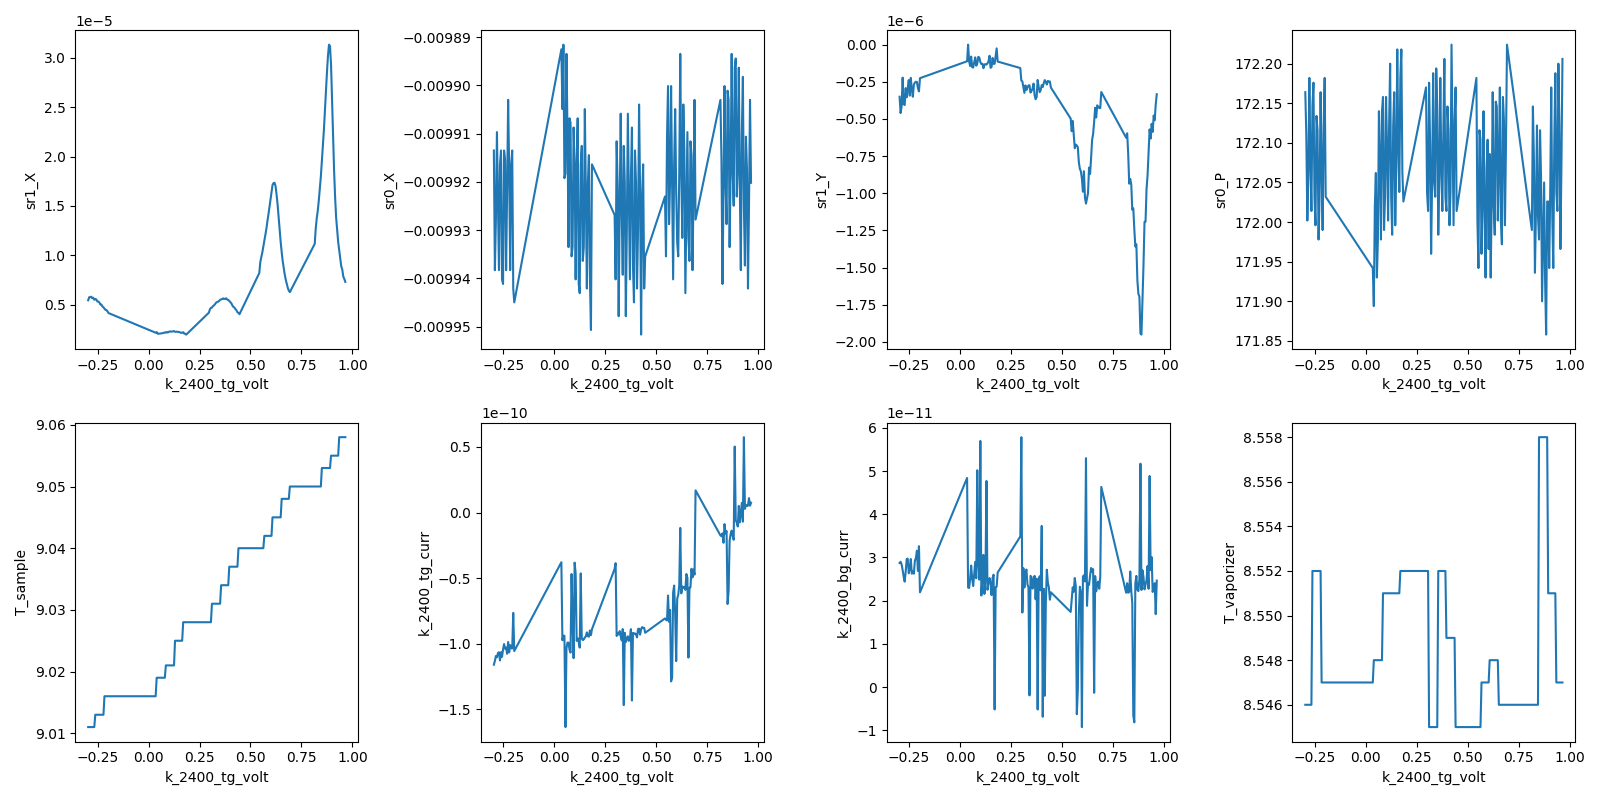

2026-08-24 01:57:43,880 [INFO] Completed in 0h 1m 32s


2026-08-24 01:57:43,880 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\13\data.tsv.gz


   run 13 done; T_sample now 9.058 K


[02:00:03] T set 13.0 -> T_sample 13.011 K (stable=True); T_vap 12.348 K; ranges 1/1
2026-08-24 02:00:03,928 [INFO] Starting multisweep with ID 14


2026-08-24 02:00:03,929 [INFO] Minimum duration 0h 1m 12s


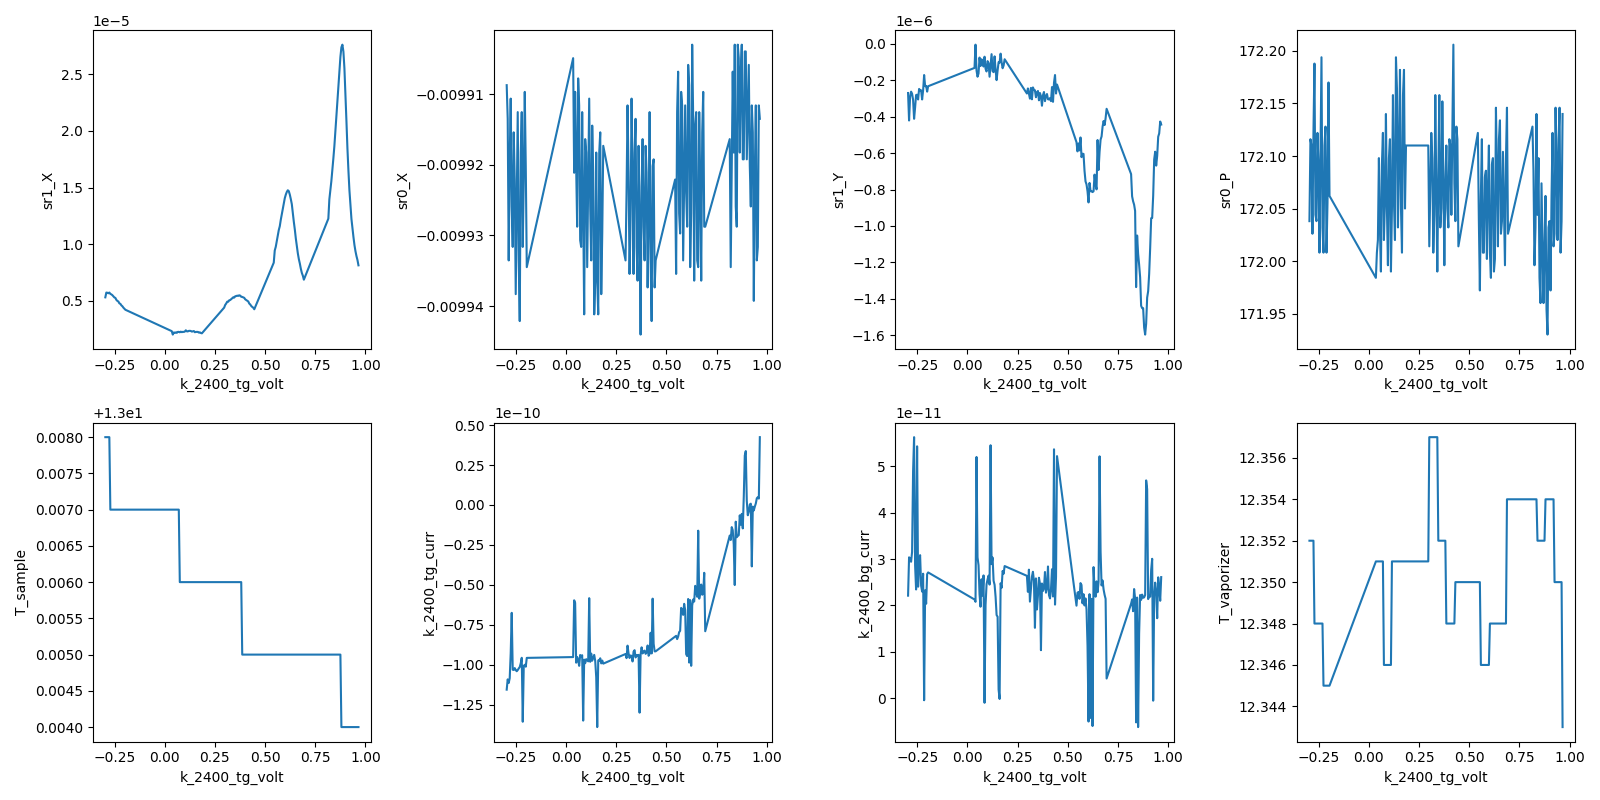

2026-08-24 02:01:37,453 [INFO] Completed in 0h 1m 32s


2026-08-24 02:01:37,454 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\14\data.tsv.gz


   run 14 done; T_sample now 13.004 K


[02:03:57] T set 18.0 -> T_sample 18.014 K (stable=True); T_vap 17.102 K; ranges 1/1
2026-08-24 02:03:57,512 [INFO] Starting multisweep with ID 15


2026-08-24 02:03:57,512 [INFO] Minimum duration 0h 1m 12s


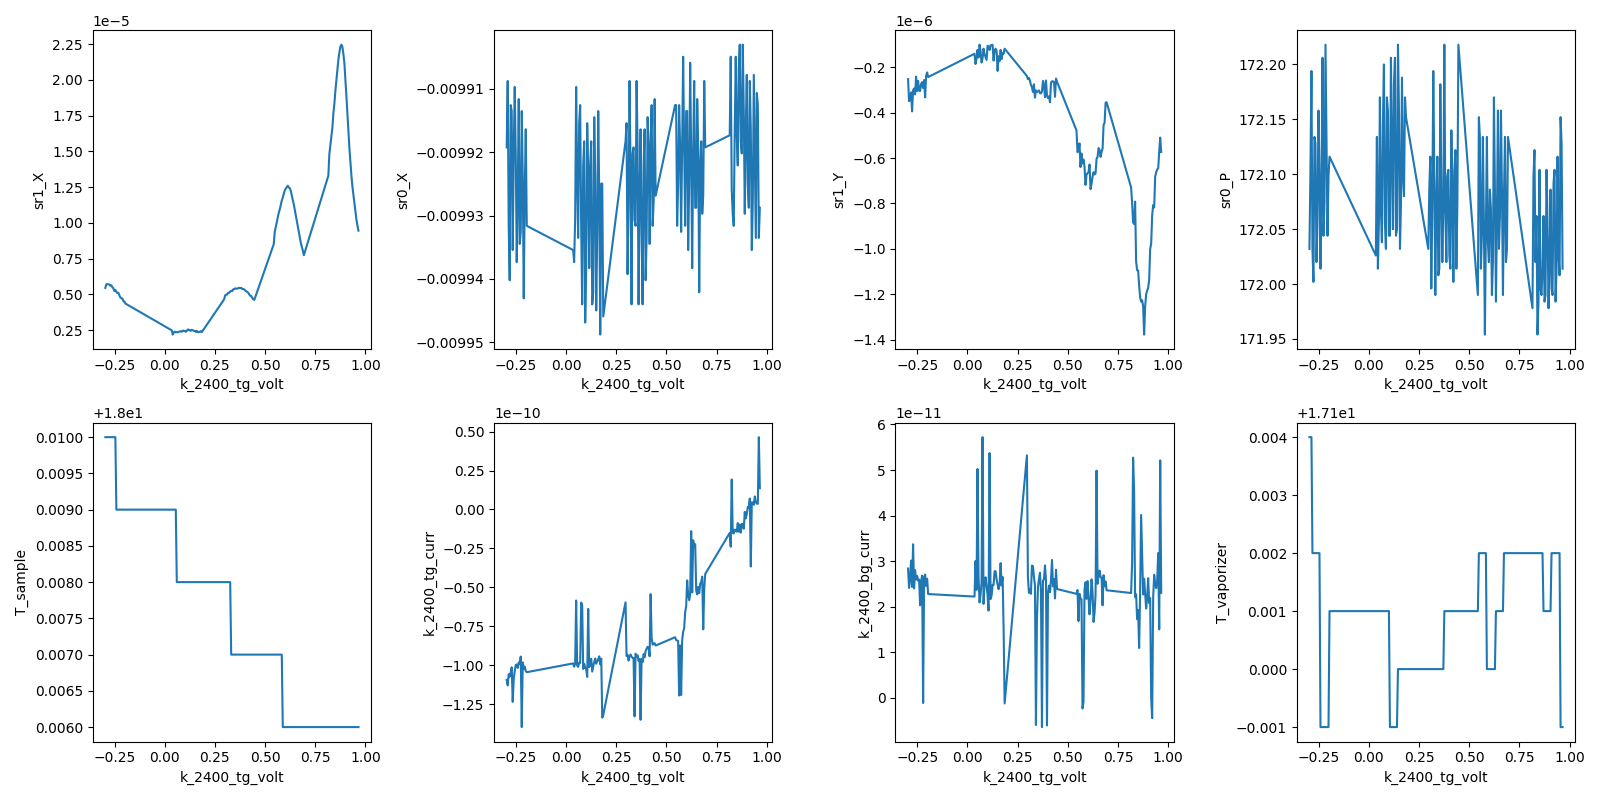

2026-08-24 02:05:31,291 [INFO] Completed in 0h 1m 33s


2026-08-24 02:05:31,292 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\15\data.tsv.gz


   run 15 done; T_sample now 18.006 K


[02:07:51] T set 25.0 -> T_sample 25.005 K (stable=True); T_vap 23.751 K; ranges 2/2
2026-08-24 02:07:51,330 [INFO] Starting multisweep with ID 16


2026-08-24 02:07:51,330 [INFO] Minimum duration 0h 1m 12s


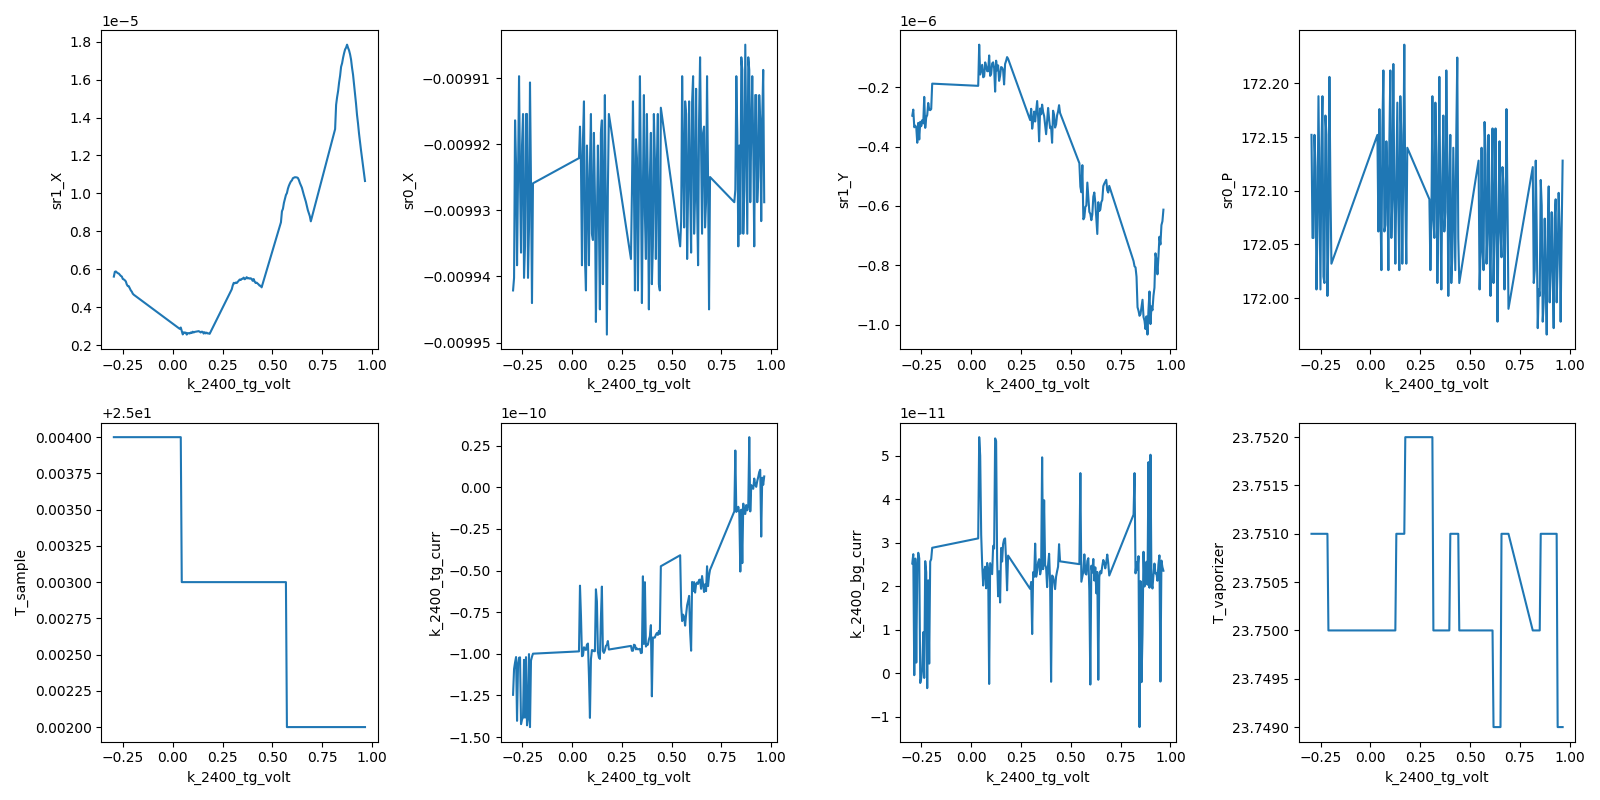

2026-08-24 02:09:25,055 [INFO] Completed in 0h 1m 32s


2026-08-24 02:09:25,056 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\16\data.tsv.gz


   run 16 done; T_sample now 25.002 K


[02:11:45] T set 35.0 -> T_sample 35.007 K (stable=True); T_vap 33.252 K; ranges 2/2
2026-08-24 02:11:45,119 [INFO] Starting multisweep with ID 17


2026-08-24 02:11:45,120 [INFO] Minimum duration 0h 1m 12s


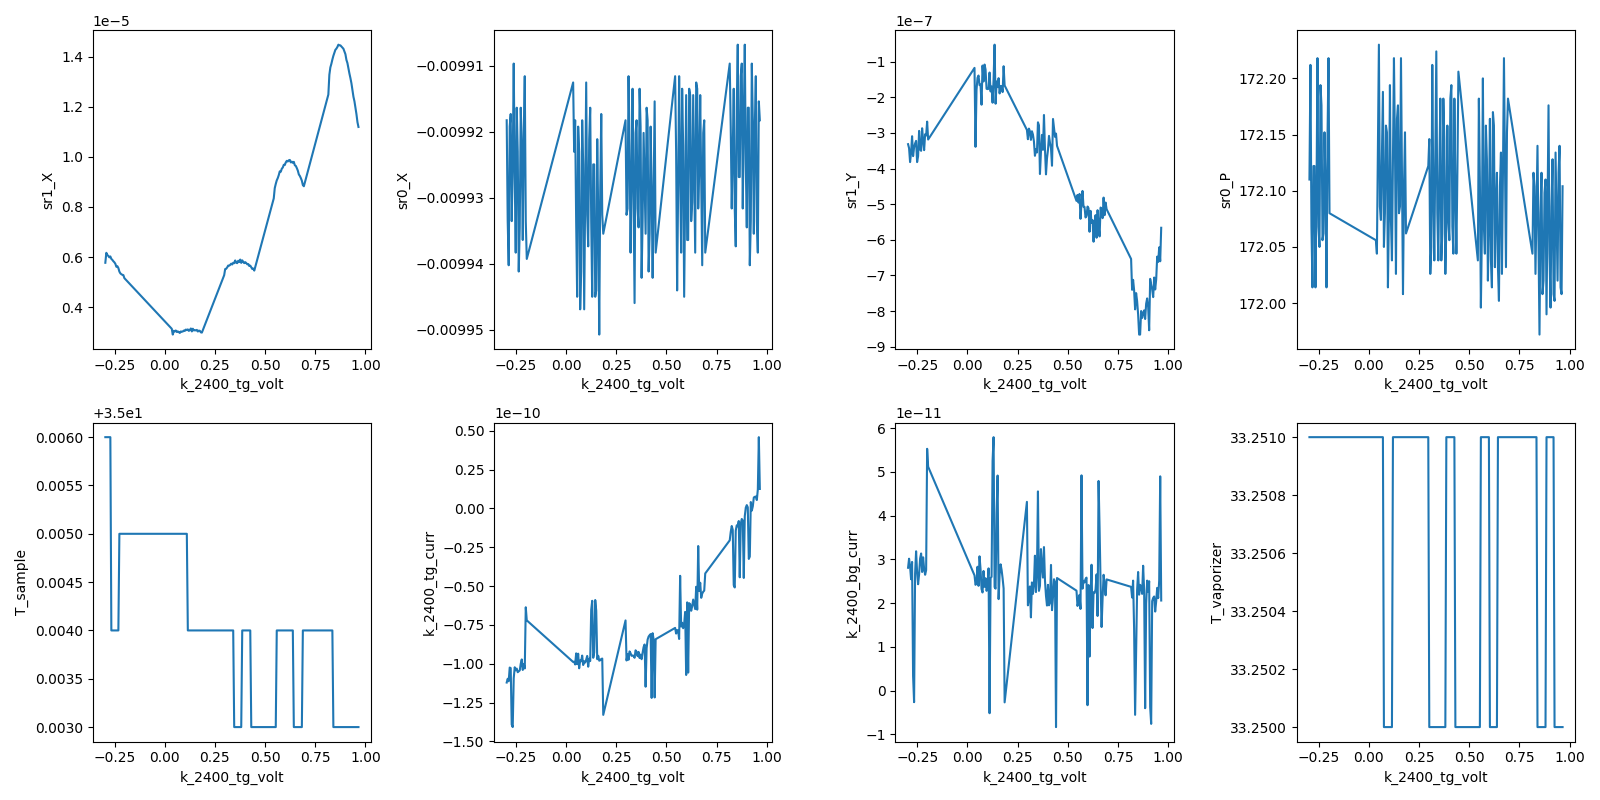

2026-08-24 02:13:18,692 [INFO] Completed in 0h 1m 32s


2026-08-24 02:13:18,692 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\17\data.tsv.gz


   run 17 done; T_sample now 35.003 K


[02:15:38] T set 50.0 -> T_sample 50.008 K (stable=True); T_vap 47.504 K; ranges 2/2
2026-08-24 02:15:38,734 [INFO] Starting multisweep with ID 18


2026-08-24 02:15:38,735 [INFO] Minimum duration 0h 1m 12s


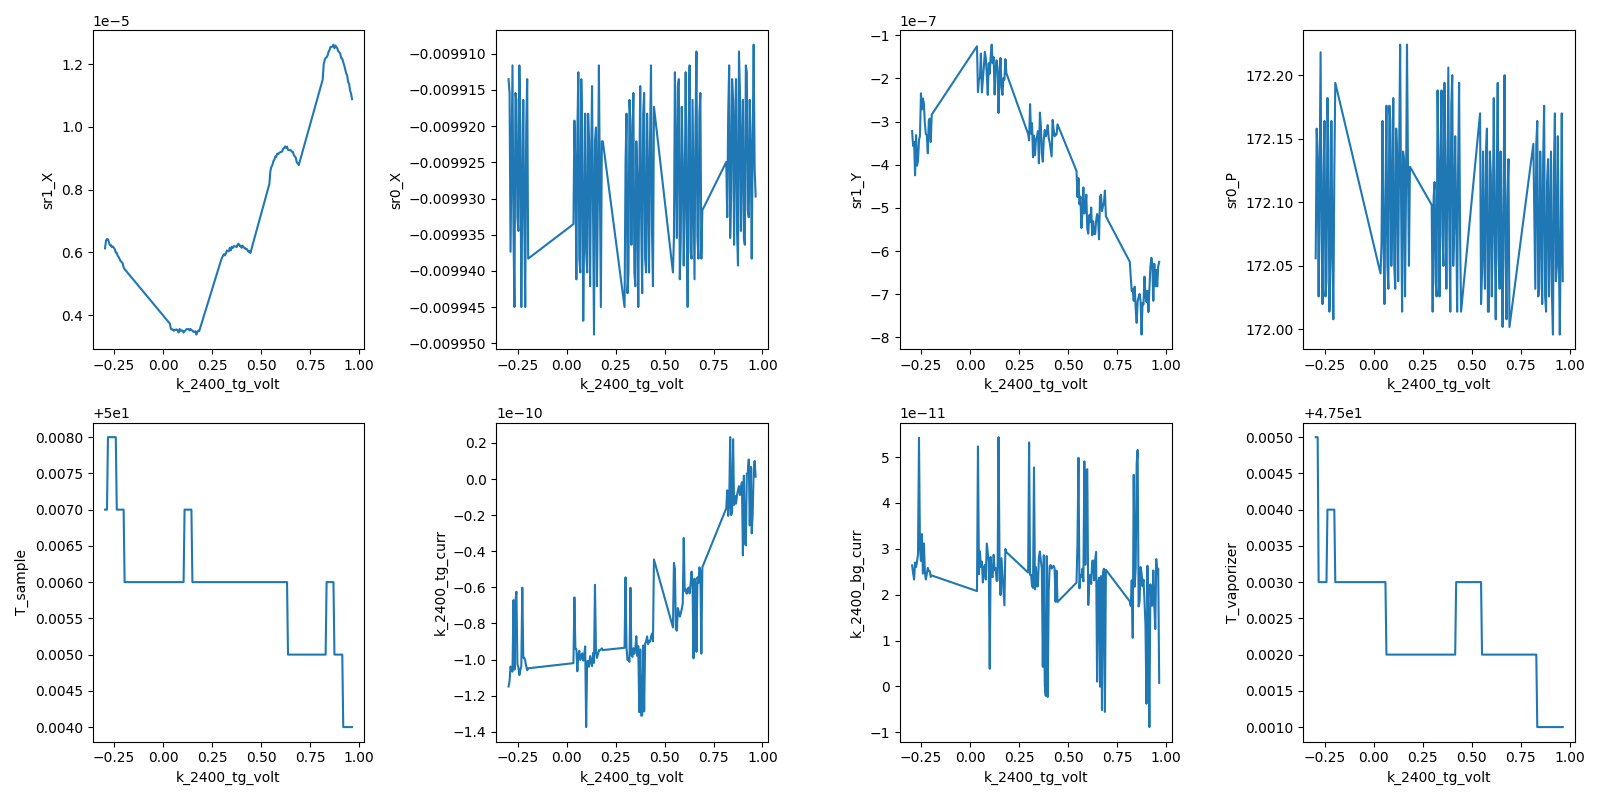

2026-08-24 02:17:11,912 [INFO] Completed in 0h 1m 32s


2026-08-24 02:17:11,913 [INFO] Data saved in C:\Users\DGG\VTI_local_data\zack\20260823-vti-02\data\18\data.tsv.gz


   run 18 done; T_sample now 50.004 K
heaters off: ranges 0/0; T_sample 50.004 K
ladder runs: [(None, 1.179, 8), (2.0, np.float64(2.0001666666666664), 9), (3.0, np.float64(3.170833333333333), 10), (4.5, np.float64(4.6345), 11), (6.5, np.float64(6.567), 12), (9.0, np.float64(9.0095), 13), (13.0, np.float64(13.010666666666665), 14), (18.0, np.float64(18.013833333333334), 15), (25.0, np.float64(25.004666666666665), 16), (35.0, np.float64(35.00666666666667), 17), (50.0, np.float64(50.00783333333333), 18)]


In [26]:
# HERA — plan step 5: temperature ladder of R_CNP at five D values (B = 0), one run per T point
_T, _B, _Vsi = T_sample(), magnet.field(), dc205.voltage()
print(f"precheck: T_sample={_T:.3f} K (want base 1.0-1.5) | B={_B:.4f} T (want |B|<0.02, not ramping: {not magnet.is_ramping()}) | "
      f"V_si={_Vsi:.3f} V (want 0) | heater ranges {heater.sample_range()}/{heater.vaporizer_range()} (want 0/0) | T_vap={T_vaporizer():.3f} K")
assert 1.0 <= _T <= 1.5, "not at base"
assert abs(_B) < 0.02 and not magnet.is_ramping(), "magnet not at zero"
assert abs(_Vsi) < 0.01, "Si not at 0 V"
for _s in (sr0, sr1):
    _s.time_constant(0.1)

# five CNP points from run 4 (V_bg, V_tg*): D-D0 ~ -0.11, 0, +0.10, +0.19, +0.28 V/nm; +/-75 mV TG window @5 mV each
_PTS = [(+0.40, -0.271), (0.00, +0.110), (-0.45, +0.371), (-0.80, +0.618), (-1.15, +0.890)]
_dv = np.round(np.arange(-0.075, 0.075 + 1e-9, 0.005), 4)
_vt_list, _vb_list = [], []
for _vb0, _vt0 in _PTS:
    _vt, _vb = sanitize_tg_bg(_vt0 + _dv, np.full_like(_dv, _vb0), tg_lims, bg_lims)
    _vt_list.append(_vt); _vb_list.append(_vb)
_vt_all = np.concatenate(_vt_list); _vb_all = np.concatenate(_vb_list)
assert _vt_all.min() >= TG_MIN and _vt_all.max() <= TG_MAX and _vb_all.min() >= BG_MIN and _vb_all.max() <= BG_MAX
T_LADDER = [None, 2.0, 3.0, 4.5, 6.5, 9.0, 13.0, 18.0, 25.0, 35.0, 50.0]   # None = base, heaters off
RATIO = 0.95
assert max(t for t in T_LADDER if t) <= T_SESSION_CAP
print(f"ladder: {len(T_LADDER)} T points, {len(_vt_all)} pts per run (~{len(_vt_all)*0.68/60:.1f} min each)")


def settle_T(target, max_wait=600, window=60, tol_frac=0.03, tol_abs=0.05):
    """Hover acceptance (rig card): accept when T_sample has been stable over `window` s, not on proximity."""
    t0 = time.time(); hist = []
    interruptible_sleep(90)
    while time.time() - t0 < max_wait:
        hist.append((time.time(), T_sample()))
        recent = [T for (tt, T) in hist if tt > time.time() - window]
        if len(recent) >= 6 and (max(recent) - min(recent)) < max(tol_frac * target, tol_abs):
            return np.mean(recent), True
        interruptible_sleep(10)
    return T_sample(), False


ladder_runs = []
for _Tset in T_LADDER:
    if _Tset is None:
        _Tnow, _ok = T_sample(), True
    else:
        heater.set_both(_Tset, ratio=RATIO)
        _Tnow, _ok = settle_T(_Tset)
    print(f"[{time.strftime('%H:%M:%S')}] T set {_Tset} -> T_sample {_Tnow:.3f} K (stable={_ok}); T_vap {T_vaporizer():.3f} K; "
          f"ranges {heater.sample_range()}/{heater.vaporizer_range()}")
    meas_config["sample_temperature:"] = T_sample()
    meas_config["Si (V)"] = dc205.voltage()
    meas_config["comments"] = f"cnp-t-ladder: T_set={_Tset} K (T_sample {_Tnow:.3f} K), 5 CNP windows (D-D0 -0.11,0,+0.10,+0.19,+0.28), B=0"
    s = sweep.AsyncStation(meas_config)
    s.fp(sr0.X).fp(sr0.P).fp(sr1.X).fp(sr1.Y).fp(k_tg.curr).fp(k_bg.curr).fp(T_sample).fp(T_vaporizer)
    s.add_comment("cnp-t-ladder")
    s.add_comment(f"T_set={_Tset} K ratio {RATIO}, T_sample at start {_Tnow:.3f} K stable={_ok}; multisweep [k_bg.volt,k_tg.volt] over 5 windows "
                  f"V_bg in {[p[0] for p in _PTS]} x TG +/-75 mV @5mV about {[p[1] for p in _PTS]}; delay 0.5 s, tau 100 ms; B=0, V_si=0; I_bias 10 nA")
    ar1 = SrAutoRange(sr1, cols=(5, 6), gain=1.0, lo=1e-6, hi=0.5)
    s.register_run_after(ar1, args=())
    for _p in (sr1.X, sr0.X, sr1.Y, sr0.P, T_sample, k_tg.curr, k_bg.curr, T_vaporizer):
        s.plot(k_tg.volt, _p)
    res = s.multisweep([k_bg.volt, k_tg.volt], [_vb_all, _vt_all], delay=0.5)
    ladder_runs.append((_Tset, _Tnow, res.id))
    print(f"   run {res.id} done; T_sample now {T_sample():.3f} K")
    if s.interrupt_requested or getattr(s, "_interrupted", False):
        print("interrupted — stopping ladder"); break

heater.off()
print(f"heaters off: ranges {heater.sample_range()}/{heater.vaporizer_range()}; T_sample {T_sample():.3f} K")
print("ladder runs:", ladder_runs)


## HERA — close-out (operator ask: return-to-initial)

> **11:15** · close-out: state0 restore, gates TG/BG/Si -> 0 V, heaters off, B -> 0, full readback · **ETA ~11:20** (≈5 min)

Session arc complete; the call (ABAB, strong) is the final ana cell. This cell restores  (drive, lock-in ranging, NPLC, all three gates to 0 V at their committed pacing — Keithley 5 mV steps, DC205 0.5 V/s), turns both heater ranges off (already off after the ladder; re-asserted), lands the field at 0 T (from the 0.003 T remanent readback), and prints the full readback. Sample is cooling passively from the 50 K ladder top.

In [27]:
# HERA — close-out on operator ask: return-to-initial (field 0, gates 0 at committed pacing,
# heaters off, state0 acquisition restore, full readback)
from sharpelab_nb.closeout import close_out
print(f"pre: B={magnet.field():.4f} T (ramping={magnet.is_ramping()}) | V_tg={k_tg.volt():.3f} V_bg={k_bg.volt():.3f} "
      f"V_si={dc205.voltage():.3f} | ranges {heater.sample_range()}/{heater.vaporizer_range()} | "
      f"T_sample={T_sample():.2f} K T_vap={T_vaporizer():.2f} K")
close_out(
    field=(magnet.field, 0.0),
    restore=state0,                       # drive/sens/tau/slope on sr0-sr3, NPLC, and V_tg=V_bg=V_si=0 (captured at bring-up; Keithley step 5 mV, DC205 0.5 V/s)
    heaters=[("heater.off(both)", heater.off)],
    extra_readback={
        "T_sample": T_sample, "T_vaporizer": T_vaporizer,
        "sample_range": heater.sample_range, "vaporizer_range": heater.vaporizer_range,
        "B_readback": magnet.field,
    },
)
print(f"post: B={magnet.field():.4f} T | V_tg={k_tg.volt():.4f} V_bg={k_bg.volt():.4f} V_si={dc205.voltage():.4f} | "
      f"ranges {heater.sample_range()}/{heater.vaporizer_range()} | T_sample={T_sample():.2f} K T_vap={T_vaporizer():.2f} K")


pre: B=0.0063 T (ramping=False) | V_tg=0.965 V_bg=-1.150 V_si=0.000 | ranges 0/0 | T_sample=1.17 K T_vap=0.95 K
-- restore (19 params)


-- heaters
   heater.off(both)
-- field -> 0.0



--- close-out readback ---
drive_V : 1.0  <Numbers 0.004<=v<=5.0>
drive_Hz : 13.777  <Numbers 0.001<=v<=102000.0>
sr0_sens : 0.02  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr0_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr0_slope : 24  <Enum: {24, 18, 12, 6}>
sr1_sens : 2e-06  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5e-08, 1e-06, 0.1, 5e-09, 2e-05, 0.02, 5e-07, 1e-05, 0.01, 2e-07, 0.005, 1e-07, 2e-06, 0.002, 0.001, 0.0005}>
sr1_tau : 0.3  <Enum: {0.3, 1, 3, 10, 10000.0, 0.0001, 30, 300, 30000.0, 3000.0, 3e-05, 0.03, 0.1, 0.0003, 100, 1e-05, 1000.0, 0.01, 0.003, 0.001}>
sr1_slope : 24  <Enum: {24, 18, 12, 6}>
sr2_sens : 0.0001  <Enum: {0.2, 0.5, 2e-09, 1, 1e-08, 5e-05, 2e-08, 0.0001, 0.05, 0.0002, 5e-06, 5

V_bg : 0.0  <Numbers -1.3<=v<=2.0>
V_si : 0.0  <Numbers -25.0<=v<=25.0>
field : 0.006334849315068492 T  <Numbers -10.0<=v<=10.0>
T_sample : 1.171
T_vaporizer : 0.948
sample_range : 0
vaporizer_range : 0
B_readback : 0.00634445205479452  <Numbers -10.0<=v<=10.0>
post: B=0.0063 T | V_tg=0.0000 V_bg=0.0000 V_si=0.0000 | ranges 0/0 | T_sample=1.17 K T_vap=0.95 K


*Erratum to the cell above: the sentence should read "restores `state0` (drive, lock-in ranging, …)" — the literal `state0` was eaten by shell quoting at append time (logged in session_notes). No effect on the executed code or the readback.*
